<a id="inicio"></a>
# PLN · Trabajo práctico 2

En este notebook resolvemos los ejercicios del TP usando las sinopsis de `libros.csv`. Vamos preparando los textos, probando distintas formas de representarlos y buscando libros con ellas.

Seguimos las celdas en orden. A lo largo del trabajo comentamos qué estamos haciendo y qué nos dicen los resultados.

**Índice:** [Preparación](#preparacion) · [Datos](#corpus) · [TF-IDF](#tfidf) · [Corpus](#analisis) · [Word2Vec](#word2vec) · [Oraciones](#oraciones) · [Comparación](#espacios) · [PostgreSQL](#persistencia) · [Filtros](#sql) · [Evaluación](#evaluacion) · [Búsqueda combinada](#hibrida) · [Archivos](#archivos)

<a id="preparacion"></a>
## Preparación en Colab

Para empezar, subimos **`libros.csv` y `queries.json`** al panel de archivos de Colab. Si falta alguno, la celda de preparación nos permite subirlo.

En el panel **Secretos** (el ícono de llave), agregamos **`SUPABASE_DB_URL`** con la URL de conexión de PostgreSQL de Supabase y habilitamos **Acceso del notebook**. Usamos la conexión del *Session pooler*, con un usuario que pueda crear las tablas del práctico. La URL queda en el secreto: no hace falta escribirla en una celda ni subir un `.env`.

Después ejecutamos las celdas en orden, o elegimos **Entorno de ejecución → Ejecutar todas**. Podemos usar CPU; si elegimos una GPU, se usa automáticamente para los modelos de oraciones.

La primera ejecución instala las dependencias y descarga los modelos. SBW es un archivo grande, de alrededor de 1 GB, así que esa descarga puede tardar varios minutos. No necesitamos subir modelos ni matrices ya calculadas.

En PostgreSQL usamos el esquema **`pln_tp2_local`**. Las secciones de base de datos actualizan los libros y recrean las cuatro tablas de embeddings del práctico dentro de ese esquema.

Al final armamos **`TP2_artifacts.zip`** con los archivos generados y lo descargamos. Los archivos de `/content` se pierden al eliminar el entorno de ejecución; el ZIP nos permite conservar lo que calculamos.

In [1]:
# Instalamos antes de importar las bibliotecas del práctico.
import subprocess
import sys

dependencias = [
    "gensim==4.4.0",
    "sentence-transformers==6.1.0",
    "transformers==5.19.0",
    "psycopg[binary]==3.3.6",
    "pgvector==0.5.1",
    "langdetect==1.0.9",
    "scikit-learn>=1.6,<2",
    "nltk>=3.9,<4",
    "numpy>=1.24",
    "scipy>=1.11",
    "pandas>=2",
    "matplotlib>=3.7",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *dependencias])
print("Dependencias listas.")

Dependencias listas.


In [2]:
from pathlib import Path
import json
import os
from urllib.parse import urlsplit
import pandas as pd

try:
    from google.colab import files, userdata
except ImportError:
    raise RuntimeError("Abrí esta versión del notebook en Google Colab.") from None

DATA_DIR = Path("/content")
DATA_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(DATA_DIR)
CARPETA = ""
ARTIFACT_DIR = DATA_DIR / "TP2_artifacts"
DB_SCHEMA = "pln_tp2_local"

def obtener_url_supabase():
    """Leemos el secreto sin mostrar su valor ni copiarlo a un archivo."""
    try:
        valor = userdata.get("SUPABASE_DB_URL")
    except Exception as error:
        tipo = type(error).__name__
        if tipo == "SecretNotFoundError":
            mensaje = "Agregá SUPABASE_DB_URL en el panel Secretos de Colab."
        elif tipo == "NotebookAccessError":
            mensaje = "Habilitá Acceso del notebook para el secreto SUPABASE_DB_URL."
        else:
            mensaje = "No pudimos leer SUPABASE_DB_URL. Revisá el panel Secretos y volvé a ejecutar esta celda."
        raise RuntimeError(mensaje) from None
    if not isinstance(valor, str) or not valor.strip():
        raise RuntimeError("El secreto SUPABASE_DB_URL está vacío.")
    valor = valor.strip()
    try:
        partes = urlsplit(valor)
        valida = partes.scheme in {"postgres", "postgresql"} and bool(partes.hostname)
    except ValueError:
        valida = False
    if not valida:
        raise RuntimeError("SUPABASE_DB_URL debe contener una URL de conexión PostgreSQL válida.")
    return valor

# Comprobamos el secreto antes de descargar los modelos.
_SUPABASE_DB_URL = obtener_url_supabase()

faltantes = [nombre for nombre in ("libros.csv", "queries.json")
             if not (DATA_DIR / nombre).is_file()]
if faltantes:
    print("Subimos los archivos que faltan:", ", ".join(faltantes))
    files.upload()
faltantes = [nombre for nombre in ("libros.csv", "queries.json")
             if not (DATA_DIR / nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Falta subir: " + ", ".join(faltantes))

datos_entrada = pd.read_csv(DATA_DIR / "libros.csv")
columnas = {"url_libro", "titulo", "autores", "generos", "serie", "sinopsis"}
if not columnas.issubset(datos_entrada.columns):
    raise ValueError("libros.csv no contiene todas las columnas usadas en el práctico: "
                     + ", ".join(sorted(columnas - set(datos_entrada.columns))))
with (DATA_DIR / "queries.json").open(encoding="utf-8") as archivo:
    consultas_entrada = json.load(archivo)
if not isinstance(consultas_entrada, dict) or not isinstance(consultas_entrada.get("consultas"), list):
    raise ValueError("queries.json debe contener una lista llamada consultas.")
del datos_entrada, consultas_entrada

def abrir_conexion_supabase(crear_esquema=False):
    """Conectamos al mismo esquema al abrir o recuperar una conexión."""
    import psycopg
    from psycopg import sql
    from pgvector.psycopg import register_vector

    conexion = None
    try:
        conexion = psycopg.connect(_SUPABASE_DB_URL, autocommit=True,
                                  sslmode="require", connect_timeout=20,
                                  prepare_threshold=None)
        if crear_esquema:
            conexion.execute("CREATE EXTENSION IF NOT EXISTS vector;")
            conexion.execute(sql.SQL("CREATE SCHEMA IF NOT EXISTS {};").format(sql.Identifier(DB_SCHEMA)))
        conexion.execute(sql.SQL("SET search_path TO {}, public;").format(sql.Identifier(DB_SCHEMA)))
        if conexion.execute("SELECT current_schema();").fetchone()[0] != DB_SCHEMA:
            raise RuntimeError("No se pudo seleccionar el esquema del práctico.")
        register_vector(conexion)
        return conexion
    except Exception:
        if conexion is not None:
            try:
                conexion.close()
            except Exception:
                pass
        raise RuntimeError(
            "No pudimos conectar o preparar PostgreSQL. Revisá la URL del Session pooler, "
            "la contraseña del secreto, la disponibilidad de la base y los permisos "
            "del usuario para el esquema pln_tp2_local y pgvector."
        ) from None

print("Entorno de Colab listo: libros.csv, queries.json y secreto de PostgreSQL disponibles.")

Entorno de Colab listo: libros.csv, queries.json y secreto de PostgreSQL disponibles.


In [3]:
import html
import platform
from importlib.metadata import version
from IPython.display import display, HTML, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelsize": 10, "font.size": 10,
    "axes.prop_cycle": cycler(color=["#2563eb", "#059669", "#d97706", "#7c3aed", "#db2777", "#475569"]),
    "figure.facecolor": "white", "axes.facecolor": "#f8fafc",
})
pd.set_option("display.max_rows", 16)
pd.set_option("display.max_columns", 14)

def tabla_resultados(datos, titulo, precision=3, formato=None):
    """Tabla compacta. Los valores siempre provienen de variables calculadas."""
    tabla = datos.to_frame() if isinstance(datos, pd.Series) else datos
    display(HTML(f"<p style='color:#1d4ed8;font-weight:600;margin-top:1em'>{html.escape(titulo)}</p>"))
    estilo = tabla.style.format(precision=precision, na_rep="—", escape="html")
    if formato:
        estilo = estilo.format(formato, na_rep="—", precision=precision, escape="html")
    display(estilo.set_table_styles([
        {"selector": "th", "props": [("background-color", "#eff6ff"), ("color", "#1e3a8a"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e2e8f0")]},
        {"selector": "caption", "props": [("text-align", "left")]},
    ]))

tabla_resultados(pd.DataFrame({
    "versión": {"Python": platform.python_version(), **{p: version(p) for p in
        ["numpy", "pandas", "scikit-learn", "gensim", "sentence-transformers", "psycopg", "pgvector"]}}
}), "Entorno de esta ejecución")

,versión
Python,3.13.16
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
gensim,4.4.0
sentence-transformers,6.1.0
psycopg,3.3.6
pgvector,0.5.1


<a id="corpus"></a>
## 1. Preparar los datos

Empezamos por leer las sinopsis. Al extraerlas quedaron algunos espacios pegados, así que los corregimos antes de seguir.

Conservamos dos versiones: `texto_crudo`, con mayúsculas y puntuación, y `texto_limpio`, en minúsculas y sin puntuación ni números. Así podemos elegir la que nos convenga según el modelo.

In [4]:
import re
import pandas as pd

df = pd.read_csv("libros.csv")

def reparar_espacios(t):
    # "acción.En" → "acción. En"
    t = re.sub(r"([a-záéíóúüñ])([.!?:;*])([A-ZÁÉÍÓÚÜÑ¿¡])", r"\1\2 \3", t)
    # "científicaABRIL" → "científica ABRIL", "1955Novelas" → "1955 Novelas"
    t = re.sub(r"([a-záéíóúüñ0-9])([A-ZÁÉÍÓÚÜÑ])", r"\1 \2", t)
    return re.sub(r"\s+", " ", t).strip()

def limpiar_bow(t):
    t = t.lower()
    t = re.sub(r"[^\w\s]", " ", t)   # puntuación → ESPACIO, no ""
    t = re.sub(r"\d+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["texto_crudo"]  = df["sinopsis"].apply(reparar_espacios)  # para SBERT (Parte C)
df["texto_limpio"] = df["texto_crudo"].apply(limpiar_bow)    # para TF-IDF y Word2Vec

In [5]:
tabla_resultados(df[["titulo", "texto_crudo", "texto_limpio"]].head(3), "Vista previa: texto natural y texto léxico")
grupos_sinopsis = df["texto_crudo"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
duplicadas = df.loc[grupos_sinopsis.duplicated(keep=False), ["titulo", "url_libro"]]
tabla_resultados(pd.DataFrame({"valor": {"Libros": len(df), "Sinopsis únicas": grupos_sinopsis.nunique(),
    "Filas con sinopsis repetida": len(duplicadas)}}), "Control de duplicados")
if len(duplicadas):
    tabla_resultados(duplicadas, "Sinopsis compartidas: mantener el grupo unido en validación cruzada")

,titulo,texto_crudo,texto_limpio
0,Más Allá 23,"Revista mensual de aventuras apasionantes en el mundo de la magia científica ABRIL 1955 Novelas cortas* Un mundo de talentos, por Philip K. Dick* Amnesia de sí mismo, por F. L. Wallace Cuentos* Asteroide cautivo, por Raymond Z. Gallun* Si Ud. fuera el único, por Richard Wilson* Llegarán las mansas lluvias, por Ray Bradbury Aventuras de la mente* Conquistador del Micromundo* El fin del mundo, por Kennet Heuer* Las edades glaciares, por Willy Ley (III)Novedades cósmicas* Correspondencia* Espaciotesty sus Respuestas* Los sobres contienen sorpresas(Editorial)",revista mensual de aventuras apasionantes en el mundo de la magia científica abril novelas cortas un mundo de talentos por philip k dick amnesia de sí mismo por f l wallace cuentos asteroide cautivo por raymond z gallun si ud fuera el único por richard wilson llegarán las mansas lluvias por ray bradbury aventuras de la mente conquistador del micromundo el fin del mundo por kennet heuer las edades glaciares por willy ley iii novedades cósmicas correspondencia espaciotesty sus respuestas los sobres contienen sorpresas editorial
1,Náufragos del anti-tiempo,"No te pierdas la nueva entrega de la exitosa saga de El Metaverso, donde cada space opera te va a llevar a explorar un nuevo universo lleno de aventuras y de acción. En Náufragos del anti-tiempo, Víctor Conde nos presenta a la familia Dandridge, quienes viven a bordo de su herencia familiar, la nave espacial El Constelación que utilizan para dirigir un negocio de entregas espaciales. Cuando Donna y Kopak se alían con los Dandridge, se unen a la tripulación de El Constelación y se ven envueltos en una conspiración intergaláctica que busca alterar el curso de la historia. Desde un misterioso planeta perdido en el tiempo hasta una Tierra futurista y distópica, los personajes deberán luchar contra el tiempo y enfrentarse a fuerzas oscuras que amenazan con destruirlos a todos. Con giros emocionantes y personajes inolvidables, este relato de ciencia ficción es imprescindible para cualquier aficionado del género. ¿Serán los héroes capaces de superar las adversidades y salvar el día, o caerán ante los peligros que les acechan? Acompáñalos en este emocionante viaje a través del espacio y el tiempo para descubrirlo. Este libro es perfecto para lectores nuevos y fans veteranos del género space opera. También es recomendada para los fans de las series de ciencia ficción como Dune, Star Wars o Star Trek.",no te pierdas la nueva entrega de la exitosa saga de el metaverso donde cada space opera te va a llevar a explorar un nuevo universo lleno de aventuras y de acción en náufragos del anti tiempo víctor conde nos presenta a la familia dandridge quienes viven a bordo de su herencia familiar la nave espacial el constelación que utilizan para dirigir un negocio de entregas espaciales cuando donna y kopak se alían con los dandridge se unen a la tripulación de el constelación y se ven envueltos en una conspiración intergaláctica que busca alterar el curso de la historia desde un misterioso planeta perdido en el tiempo hasta una tierra futurista y distópica los personajes deberán luchar contra el tiempo y enfrentarse a fuerzas oscuras que amenazan con destruirlos a todos con giros emocionantes y personajes inolvidables este relato de ciencia ficción es imprescindible para cualquier aficionado del género serán los héroes capaces de superar las adversidades y salvar el día o caerán ante los peligros que les acechan acompáñalos en este emocionante viaje a través del espacio y el tiempo para descubrirlo este libro es perfecto para lectores nuevos y fans veteranos del género space opera también es recomendada para los fans de las series de ciencia ficción como dune star wars o star trek
2,Una rosa en el paraíso,"René Barjavel, consagrado autor de La noche de los tiempos y los caminos a Katmandú, retoma aquí uno de sus temas predilectos: el fin del mundo. La acción se sitúa en un futuro más o menos próxi

,valor
Libros,200
Sinopsis únicas,199
Filas con sinopsis repetida,2


,titulo,url_libro
36,La gran aventura de Norby,https://ww3.lectulandia.co/book/la-gran-aventura-de-norby/
38,Norby regresa a la Tierra,https://ww3.lectulandia.co/book/norby-regresa-a-la-tierra/


Vemos que los textos "limpios" resultan de hecho menos legibles que los "sucios", gracias a la ausencia de mayúsculas y, sobre todo, signos de puntuación. Los acentos, en cambio, se conservan en esta limpieza. Para TF-IDF, pasar a minúsculas nos permite contar juntas formas como "Tierra" y "tierra".

Observamos también que hay dos URLs que presentan exactamente la misma sinopsis. Mantenemos ambos libros en el corpus, pero agrupamos sus sinopsis al evaluar para que esa repetición no se reparta entre entrenamiento y prueba.

<a id="tfidf"></a>
## 2. TF-IDF

Ahora probamos una primera búsqueda con TF-IDF. La idea es darle más peso a las palabras que ayudan a distinguir una sinopsis del resto.

Usamos `min_df=2`, por lo que dejamos fuera las palabras que aparecen en un solo libro. Esto nos ayuda a reducir el vocabulario y la variabilidad ante distintos corpus, como se analizará más adelante. Si una consulta no tiene ninguna palabra del vocabulario, devolvemos una lista vacía: no tendríamos con qué compararla.

In [6]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words=stopwords.words("spanish"))
X_tfidf = tfidf.fit_transform(df["texto_limpio"])
vocab = tfidf.get_feature_names_out()
print(X_tfidf.shape)


def buscar_tfidf(consulta, k):
    """Interfaz común: (consulta, k) -> (índices de fila, similitudes)."""
    q = tfidf.transform([limpiar_bow(consulta)])
    if q.nnz == 0:
        return [], []
    sims = cosine_similarity(q, X_tfidf).ravel()
    top = np.argsort(-sims, kind="stable")[:k]
    return list(top), list(sims[top])

def mostrar_tfidf(consulta, k=5):
    """Solo para mirar resultados: devuelve una tabla legible."""
    idx, sims = buscar_tfidf(consulta, k)
    return df.loc[idx, ["titulo"]].assign(similitud=np.round(sims, 3))
print(f"Matriz TF-IDF: {X_tfidf.shape[0]} libros × {X_tfidf.shape[1]} términos "
      f"| densidad {X_tfidf.nnz / np.prod(X_tfidf.shape):.2%}")

display(mostrar_tfidf("viajes en el tiempo"))
display(mostrar_tfidf("una novela sobre piratas"))

(200, 2181)
Matriz TF-IDF: 200 libros × 2181 términos | densidad 2.22%


,titulo,similitud
130,Un puente sobre el tiempo,0.235
178,Pansexualactic,0.189
63,Saga la Fundación,0.095
103,La chica del átomo de oro,0.090
1,Náufragos del anti-tiempo,0.064


,titulo,similitud
80,El Planeta prodigioso,0.206
139,La guerra de los mundos (Ilustrado por Alvim C...,0.175
173,El mundo perdido (trad. Amando Lázaro Ros),0.157
121,Somnium,0.143
127,Cuentos futuristas,0.130


In [7]:
tabla_resultados(pd.DataFrame({"valor": {"Documentos": X_tfidf.shape[0], "Términos": X_tfidf.shape[1],
       "Densidad": f"{X_tfidf.nnz / np.prod(X_tfidf.shape):.2%}"}}), "Línea de base léxica")
# posiciones distintas de 0   ^^^   / total (caracterísicas * sinopsis)

,valor
Documentos,200
Términos,2181
Densidad,2.22%


La matriz tiene 200 filas, una por libro, y 2181 columnas, una por término. La mayoría de los valores son cero (98%): cada sinopsis usa solo una parte del vocabulario.

En los ejemplos vemos que TF-IDF puede traer libros por palabras compartidas, que, con solo ver el título, parecen similares, o al menos dentro del género sci-fi. Aunque eso todavía no nos asegura que sean relevantes para lo que queríamos buscar, y los valores de similitud son en realidad muy bajos.

<a id="analisis"></a>
## 3. Analizar el corpus

Con esta primera búsqueda lista, volvemos a los datos para responder las cuatro preguntas del enunciado. Nos interesa ver qué términos distinguen las sinopsis, cuánto aparece el texto promocional, cómo funcionan las etiquetas y si encontramos textos en otros idiomas.

In [8]:
import langdetect

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

SW = stopwords.words("spanish")
pd.set_option("display.width", 200)
rng = np.random.default_rng(42)   # semilla fija: los resultados son reproducibles

In [9]:
df = pd.read_csv("libros.csv")

def reparar_espacios(t):
    # get_text(strip=True) pegó los párrafos: "acción.En" → "acción. En"
    t = re.sub(r"([a-záéíóúüñ])([.!?:;*])([A-ZÁÉÍÓÚÜÑ¿¡])", r"\1\2 \3", t)
    # "científicaABRIL" → "científica ABRIL", "1955Novelas" → "1955 Novelas"
    t = re.sub(r"([a-záéíóúüñ0-9])([A-ZÁÉÍÓÚÜÑ])", r"\1 \2", t)
    return re.sub(r"\s+", " ", t).strip()

def limpiar_bow(t):
    t = t.lower()
    t = re.sub(r"[^\w\s]", " ", t)   # puntuación → ESPACIO, no ""
    t = re.sub(r"\d+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["texto_crudo"]  = df["sinopsis"].apply(reparar_espacios)   # para SBERT (Parte C)
df["texto_limpio"] = df["texto_crudo"].apply(limpiar_bow)     # para TF-IDF y Word2Vec

# Géneros como lista, sin "Ciencia ficción" (lo tienen los 200 libros: no informa nada)
df["generos_lista"] = df["generos"].str.split(",").apply(
    lambda l: [g.strip() for g in l if g.strip() != "Ciencia ficción"])
print(df.shape)

(200, 12)


### 3.1. ¿Cuántas sinopsis hacen falta para obtener términos estables?

Nos preguntamos si los términos más importantes de una sinopsis cambian mucho según los libros que que forman el corpus para tf-idf. Para verlo, armamos dos grupos de libros de cada tamaño y comparamos sus diez términos principales.

Usamos Jaccard: vale 1 si las listas coinciden y 0 si no comparten términos. Si dos palabras tienen el mismo peso, mantenemos el orden fijo del vocabulario, que es alfabético. Así, los mismos pesos siempre nos dan el mismo top 10. Ese criterio puede aumentar la coincidencia cuando hay muchos empates.

Jaccard medio entre los top-10 de dos corpus disjuntos:
      mean    std
n                
12   0.805  0.159
25   0.743  0.170
50   0.709  0.176
75   0.683  0.177
100  0.674  0.176

Sinopsis cuyo top-10 se decide por un empate en el corte: 91.5%

Proporción del vocabulario con df = 1:
n
12     0.892
25     0.840
50     0.779
100    0.718
150    0.687
200    0.665
Name: hapax, dtype: float64
n estimado para bajar a 50% de hápax ≈ 1,465 sinopsis
n estimado para bajar a 40% de hápax ≈ 4,937 sinopsis


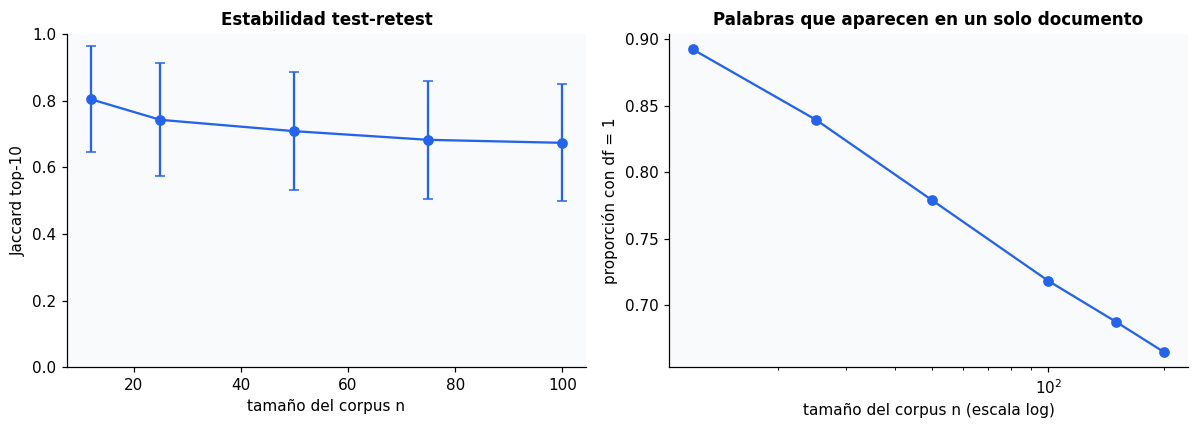

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words=SW)
Cnt = cv.fit_transform(df["texto_limpio"]).toarray()   # conteos tf(t, d), matriz 200 × V
Pres = (Cnt > 0).astype(int)                            # presencia de t en d
n_docs = Cnt.shape[0]
K = 10

def pesos_tfidf(d, S):
    """Pesos TF-IDF de la sinopsis d con el IDF estimado en el corpus S ∪ {d}
    (misma fórmula que TfidfVectorizer con sublinear_tf=True y smooth_idf=True)."""
    n = len(S) + 1
    df_t = Pres[S].sum(axis=0) + Pres[d]
    idf = np.log((1 + n) / (1 + df_t)) + 1
    tf = Cnt[d]
    return np.where(tf > 0, (1 + np.log(np.maximum(tf, 1))) * idf, 0.0)

def top_k(w):
    # Si los pesos empatan, conservamos el orden fijo del vocabulario.
    orden = np.argsort(-w, kind="stable")[:K]
    return set(orden[w[orden] > 0])

def jaccard(a, b):
    return len(a & b) / len(a | b)

# --- Medición 1: estabilidad test-retest del top-10 según el tamaño del corpus
TAMANOS = [12, 25, 50, 75, 100]
R = 10   # repeticiones por sinopsis y tamaño
filas = []
for n in TAMANOS:
    for d in range(n_docs):
        otros = np.delete(np.arange(n_docs), d)
        for _ in range(R):
            perm = rng.permutation(otros)
            S_a, S_b = perm[:n-1], perm[n-1:2*(n-1)]          # dos corpus disjuntos
            filas.append({"n": n, "jaccard": jaccard(top_k(pesos_tfidf(d, S_a)),
                                                     top_k(pesos_tfidf(d, S_b)))})
estabilidad = pd.DataFrame(filas).groupby("n")["jaccard"].agg(["mean", "std"]).round(3)
print("Jaccard medio entre los top-10 de dos corpus disjuntos:")
print(estabilidad)

# --- Medición 2: ¿en cuántas sinopsis el puesto 10 está empatado? (corpus completo)
cruza = []
for d in range(n_docs):
    s = np.sort(pesos_tfidf(d, np.delete(np.arange(n_docs), d)))[::-1]
    s = s[s > 0]
    cruza.append(len(s) > K and np.isclose(s[K], s[K-1]))
print(f"\nSinopsis cuyo top-10 se decide por un empate en el corte: {np.mean(cruza):.1%}")

# --- Medición 3: proporción de palabras que aparecen en UN solo documento (hápax de documento)
filas = []
for n in [12, 25, 50, 100, 150, 200]:
    for _ in range(20):
        S = rng.choice(n_docs, n, replace=False)
        df_S = Pres[S].sum(axis=0)
        df_S = df_S[df_S > 0]
        filas.append({"n": n, "hapax": (df_S == 1).mean()})
hapax = pd.DataFrame(filas).groupby("n")["hapax"].mean()
print("\nProporción del vocabulario con df = 1:")
print(hapax.round(3))

# Extrapolación (con cautela): ajuste lineal de la proporción de hápax contra log(n)
pend, ord_ = np.polyfit(np.log(hapax.index), hapax.values, 1)
for objetivo in [0.5, 0.4]:
    print(f"n estimado para bajar a {objetivo:.0%} de hápax ≈ {np.exp((objetivo - ord_) / pend):,.0f} sinopsis")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(estabilidad.index, estabilidad["mean"], yerr=estabilidad["std"], marker="o", capsize=3)
ax[0].set(xlabel="tamaño del corpus n", ylabel="Jaccard top-10", title="Estabilidad test-retest", ylim=(0, 1))
ax[1].plot(hapax.index, hapax.values, marker="o")
ax[1].set(xscale="log", xlabel="tamaño del corpus n (escala log)", ylabel="proporción con df = 1",
          title="Palabras que aparecen en un solo documento")
plt.tight_layout(); plt.show()

Para ver qué palabras aparecen en un top 10, mostramos tres ejemplos usando las **200 sinopsis** para calcular el IDF. Cada sinopsis tiene sus propios términos: no hay un único top 10 para todo el corpus. Los mostramos de mayor a menor peso.

Esta tabla nos sirve para interpretar la prueba de arriba. En esa prueba comparamos dos grupos de libros de cada tamaño; no los comparamos con el corpus completo.

In [11]:
# Top 10 de cada sinopsis, con el IDF calculado sobre los 200 libros.
vocabulario = cv.get_feature_names_out()
filas_top10 = []
for d in range(n_docs):
    otros = np.delete(np.arange(n_docs), d)
    pesos = pesos_tfidf(d, otros)
    seleccionados = top_k(pesos)
    ordenados = [i for i in np.argsort(-pesos, kind="stable") if i in seleccionados]
    filas_top10.append({
        "Libro": df.iloc[d]["titulo"],
        "Top 10 (de mayor a menor peso)": ", ".join(vocabulario[ordenados]),
    })

top10_corpus_completo = pd.DataFrame(filas_top10)
tabla_resultados(top10_corpus_completo.head(3), "Ejemplos de top 10 con el corpus de 200 sinopsis")

,Libro,Top 10 (de mayor a menor peso)
0,Más Allá 23,"abril, amnesia, cautivo, gallun, iii, llegarán, lluvias, mansas, sobres, ud"
1,Náufragos del anti-tiempo,"constelación, dandridge, opera, space, star, fans, personajes, género, tiempo, acompáñalos"
2,Una rosa en el paraíso,"barjavel, arca, crimen, amor, paso, abrirse, consagrado, deba, dramáticas, duda"


Vemos que aún con 200 libros, los términos más distintivos de una sinopsis son en su mayoría bastante comunes y poco ilustrativos para la temática. Aparecen términos meta/promocionales como "fans", "género", "personajes", "acompáñalos", etc.

In [12]:
tabla_resultados(estabilidad.rename(columns={"mean": "Jaccard medio", "std": "Desvío"}), "Estabilidad test–retest del top-10")
display(Markdown(f"Vemos un Jaccard medio entre **{estabilidad['mean'].iloc[0]:.3f}** y **{estabilidad['mean'].iloc[-1]:.3f}**. El último puesto del top 10 queda empatado en **{np.mean(cruza):.1%}** de las sinopsis."))

,Jaccard medio,Desvío
n,,
12,0.805,0.159
25,0.743,0.170
50,0.709,0.176
75,0.683,0.177
100,0.674,0.176


Vemos un Jaccard medio entre **0.805** y **0.674**. El último puesto del top 10 queda empatado en **91.5%** de las sinopsis.

Vemos que el Jaccard medio pasa de 0,805 a 0,674 al aumentar el tamaño del corpus. Además, muchos top 10 quedan definidos por un empate en el último puesto.

Con estos 200 libros todavía hay muchas palabras que aparecen una sola vez. La extrapolación nos da una idea de cuánto podría hacer falta ampliar el corpus, pero no la tomamos como una cantidad exacta. Lo que está claro es que se necesitan muchos más libros para obtener una

### 3.2. ¿Influye el texto promocional en la clasificación?

Una sinopsis no siempre habla solo de la historia: también puede mencionar premios, autores o ediciones. Buscamos ese vocabulario y después miramos qué palabras usa el clasificador para predecir cada género. Así podemos ver si está aprovechando información sobre el libro además de su contenido.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Vocabulario promocional o "meta" (sobre el libro, no sobre la historia)
PROMO = ["autor", "autora", "escritor", "edición", "lectores", "lector", "obra", "premio", "premios",
         "hugo", "nebula", "clásico", "clásicos", "maestro", "magistral", "apasionante", "fascinante",
         "imprescindible", "extraordinario", "brillante", "genial", "éxito", "best", "seller", "traducción",
         "ilustrada", "ilustraciones", "publicada", "publicado", "colección", "antología", "libro",
         "novela", "relatos", "cuentos", "género", "mejor", "mejores", "famoso", "célebre", "saga", "trilogía"]

presencia = pd.Series({w: df["texto_limpio"].str.contains(rf"\b{w}\b").mean() for w in PROMO})
print("Términos promocionales/meta más frecuentes (proporción de sinopsis que los contienen):")
print(presencia.sort_values(ascending=False).head(15).round(3).to_string())
patron = r"\b(?:" + "|".join(PROMO) + r")\b"
print(f"\nSinopsis con al menos uno: {df['texto_limpio'].str.contains(patron).mean():.1%}")

# 2. ¿Qué palabras pesan más para predecir cada género?
tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words=SW)
X_tfidf = tfidf.fit_transform(df["texto_limpio"])
vocab = tfidf.get_feature_names_out()

print("\nPalabras con mayor coeficiente positivo por género:")
for genero in ["Relato", "Fantástico", "Distopía", "Juvenil"]:
    y = df["generos_lista"].apply(lambda l: genero in l).astype(int)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=10).fit(X_tfidf, y)
    top = np.argsort(-clf.coef_[0])[:12]
    print(f"  {genero:<11} ({y.sum():>3} libros): {', '.join(vocab[j] for j in top)}")

Términos promocionales/meta más frecuentes (proporción de sinopsis que los contienen):
novela        0.215
obra          0.120
autor         0.105
relatos       0.100
mejor         0.090
saga          0.080
género        0.075
libro         0.070
lector        0.065
cuentos       0.065
lectores      0.060
colección     0.050
fascinante    0.045
antología     0.045
edición       0.045

Sinopsis con al menos uno: 64.5%

Palabras con mayor coeficiente positivo por género:
  Relato      ( 39 libros): relatos, cuentos, revista, antología, editorial, reunidos, aventuras, científica, literatura, dar, escritor, género
  Fantástico  ( 36 libros): jedi, sanderson, brandon, carl, magia, cuentos, editorial, fantasía, millones, trilogía, respuestas, encuentran
  Distopía    ( 10 libros): lúcida, felicidad, distopías, inglesa, escritoras, españolas, escrita, castellano, motor, literatura, scafati, artificiales
  Juvenil     (  8 libros): xoni, sintió, robot, habla, vista, difíciles, motor, actuar, c

In [14]:
tabla_resultados(presencia.sort_values(ascending=False).head(10).rename("Sinopsis con el término"), "Vocabulario sobre el libro como producto", formato={"Sinopsis con el término": "{:.1%}"})
display(Markdown(f"Encontramos al menos una palabra de la lista en **{df['texto_limpio'].str.contains(patron).mean():.1%}** de las sinopsis."))

,Sinopsis con el término
novela,21.5%
obra,12.0%
autor,10.5%
relatos,10.0%
mejor,9.0%
saga,8.0%
género,7.5%
libro,7.0%
lector,6.5%
cuentos,6.5%


Encontramos al menos una palabra de la lista en **64.5%** de las sinopsis.

Encontramos al menos una palabra de la lista en el 64,5 % de las sinopsis. Al mirar el clasificador aparecen términos como “antología” y “editorial” entre los que más pesan para algunas etiquetas.

La lista mezcla palabras de venta con otras como “novela” o “relatos”, que también describen el formato. Por eso no interpretamos toda coincidencia como publicidad.

### 3.3. Clasificación con una o varias etiquetas

Un libro puede ser una novela y, al mismo tiempo, una distopía. Por eso probamos tanto elegir una sola etiqueta como predecir varias.

Para saber si el modelo aporta algo, lo comparamos con elegir al azar y con asignar siempre las etiquetas más frecuentes. Mantenemos juntas las sinopsis repetidas al dividir los datos: una copia no debería quedar para entrenar y la otra para evaluar.

In [15]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, hamming_loss, f1_score, classification_report

# Etiquetas con al menos 8 libros (con menos, una validación cruzada de 5 particiones no tiene sentido)
MIN_EJ = 8
cuenta = pd.Series([g for l in df["generos_lista"] for g in l]).value_counts()
print("Frecuencia de géneros (sin 'Ciencia ficción'):", cuenta.to_dict())
etiquetas = cuenta[cuenta >= MIN_EJ].index.tolist()

mlb = MultiLabelBinarizer(classes=etiquetas)
Y = mlb.fit_transform(df["generos_lista"].apply(lambda l: [g for g in l if g in etiquetas]))
print(f"\nMatriz de etiquetas Y: {Y.shape} | etiquetas por libro (media): {Y.sum(1).mean():.2f}")
print("\nCo-ocurrencia de géneros (Yᵀ Y; la diagonal es la frecuencia):")
print(pd.DataFrame(Y.T @ Y, index=etiquetas, columns=etiquetas))

# Modelo multi-etiqueta: un clasificador binario por género, evaluado con validación cruzada
modelo = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words=SW),
                       OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight="balanced")))
grupos_cv = pd.util.hash_pandas_object(grupos_sinopsis, index=False).to_numpy()
cv_grupos = GroupKFold(5, shuffle=True, random_state=42)
for entrenamiento, prueba in cv_grupos.split(df["texto_limpio"], Y, groups=grupos_cv):
    assert set(grupos_cv[entrenamiento]).isdisjoint(grupos_cv[prueba]), "Fuga entre folds"
Y_pred = cross_val_predict(modelo, df["texto_limpio"], Y, groups=grupos_cv, cv=cv_grupos)

# Pisos
prev = Y.mean(axis=0)
Y_azar = (rng.random(Y.shape) < prev).astype(int)                  # azar con la prevalencia real
Y_mayoritaria = np.tile((prev >= 0.5).astype(int), (len(Y), 1))    # siempre las etiquetas de más del 50 %

def metricas(Yp):
    return {"exact_match":  accuracy_score(Y, Yp),
            "hamming_loss": hamming_loss(Y, Yp),
            "F1_micro":     f1_score(Y, Yp, average="micro", zero_division=0),
            "F1_macro":     f1_score(Y, Yp, average="macro", zero_division=0)}

print("\nMulti-etiqueta (validación cruzada, 5 particiones):")
print(pd.DataFrame({"modelo": metricas(Y_pred), "piso_azar": metricas(Y_azar),
                    "piso_mayoritaria": metricas(Y_mayoritaria)}).round(3))
print(classification_report(Y, Y_pred, target_names=etiquetas, zero_division=0))

# Comparación: forzar UNA etiqueta por libro (multi-clase), tomando el primer género listado
print("Orden en que aparecen los géneros en el CSV (primeros 3 libros):", df["generos"].head(3).tolist())
y_mc = df["generos_lista"].apply(lambda l: l[0] if l else "Sin género")
frec = y_mc.value_counts()
ok = y_mc.isin(frec[frec >= 5].index)
modelo_mc = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, stop_words=SW),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
pred_mc = cross_val_predict(modelo_mc, df.loc[ok, "texto_limpio"], y_mc[ok],
                            groups=grupos_cv[ok.to_numpy()],
                            cv=StratifiedGroupKFold(5, shuffle=True, random_state=42))
print("\nMulti-clase con el primer género:", frec[frec >= 5].to_dict())
print(f"accuracy = {accuracy_score(y_mc[ok], pred_mc):.3f} | "
      f"piso (clase mayoritaria) = {(y_mc[ok] == y_mc[ok].mode()[0]).mean():.3f} | "
      f"F1 macro = {f1_score(y_mc[ok], pred_mc, average='macro'):.3f}")

Frecuencia de géneros (sin 'Ciencia ficción'): {'Novela': 161, 'Relato': 39, 'Fantástico': 36, 'Distopía': 10, 'Aventuras': 10, 'Publicaciónes periódicas': 9, 'Juvenil': 8, 'Intriga': 8, 'Humor': 6, 'Filosófico': 3, 'Psicológico': 3, 'Otros': 3, 'Terror': 2, 'Infantil': 2, 'Histórico': 1, 'Referencia': 1, 'Historia': 1, 'Astronomía': 1, 'Policíaco': 1, 'Ucronía': 1, 'Crítica y teoría literaria': 1, 'Ensayo': 1, 'Romántico': 1}

Matriz de etiquetas Y: (200, 8) | etiquetas por libro (media): 1.41

Co-ocurrencia de géneros (Yᵀ Y; la diagonal es la frecuencia):
                          Novela  Relato  Fantástico  Distopía  Aventuras  Publicaciónes periódicas  Juvenil  Intriga
Novela                       161       0          20         7          9                         0        8        7
Relato                         0      39          16         3          1                         9        0        1
Fantástico                    20      16          36         0          1         

In [16]:
tabla_resultados(pd.DataFrame({"Modelo (CV por grupos)": metricas(Y_pred), "Azar": metricas(Y_azar),
    "Etiquetas mayoritarias": metricas(Y_mayoritaria)}).T, "Clasificación multi-etiqueta · comparación con pisos")
display(Markdown(f"Obtenemos un F1 micro de **{f1_score(Y, Y_pred, average='micro', zero_division=0):.3f}** y un F1 macro de **{f1_score(Y, Y_pred, average='macro', zero_division=0):.3f}**."))

,exact_match,hamming_loss,F1_micro,F1_macro
Modelo (CV por grupos),0.690,0.056,0.823,0.446
Azar,0.230,0.175,0.509,0.176
Etiquetas mayoritarias,0.575,0.099,0.669,0.111


Obtenemos un F1 micro de **0.823** y un F1 macro de **0.446**.

El modelo supera las dos referencias, pero no funciona igual de bien para todas las etiquetas. “Novela” obtiene un F1 de 0,95, mientras que “Aventuras”, “Juvenil” e “Intriga” quedan en cero.

Vemos entonces por qué conviene mirar cada etiqueta: el F1 micro de 0,823, por sí solo, nos daría una impresión demasiado favorable de cómo clasifica los géneros menos frecuentes.

### 3.4. Detectar el idioma antes de tokenizar

Antes de tokenizar todo como español, comprobamos el idioma. Primero le damos a `langdetect` unas frases que conocemos y luego pasamos las sinopsis.

El detector no incluye gallego, así que también buscamos algunas palabras características del gallego y del catalán. Nos sirven como pistas para revisar los textos.

In [17]:
from langdetect import detect_langs, DetectorFactory
DetectorFactory.seed = 0   # langdetect es aleatorio: sin semilla, dos corridas pueden diferir

# Palabras funcionales que existen en gallego o catalán pero no en español
MARCAS_GL = {"unha", "unhas", "non", "coa", "coas", "polo", "pola", "nunha", "xa", "moi", "tamén",
             "cando", "cunha", "isto", "iso", "dun", "dunha"}
MARCAS_CA = {"amb", "els", "és", "dels", "als", "pel", "però", "també", "més", "aquest", "aquesta",
             "seva", "molt", "quan", "sense", "fins", "què", "nau", "llunyana"}

def perfil_idioma(texto_crudo):
    r = detect_langs(texto_crudo)[0]
    toks = limpiar_bow(texto_crudo).split()
    return pd.Series({"langdetect": r.lang, "prob": round(r.prob, 3),
                      "marcas_gl": sum(w in MARCAS_GL for w in toks) / len(toks),
                      "marcas_ca": sum(w in MARCAS_CA for w in toks) / len(toks)})

# Validación con frases de control
control = pd.Series({
    "gallego":  "Nunha galaxia afastada, unha tripulación descobre que a nave non ten piloto e que o tempo xa non avanza.",
    "español":  "En una galaxia lejana, una tripulación descubre que la nave no tiene piloto y que el tiempo ya no avanza.",
    "catalán":  "En una galàxia llunyana, una tripulació descobreix que la nau no té pilot i que el temps ja no avança."})
print("Validación del detector:")
print(control.apply(perfil_idioma).round(3))

# Aplicación al corpus
perfil = df["texto_crudo"].apply(perfil_idioma)
df = df.drop(columns=perfil.columns, errors="ignore").join(perfil)
UMBRAL = 0.03   # 3 % de los tokens son marcas exclusivas
df["sospechoso"] = (df["langdetect"] != "es") | (df["marcas_gl"] > UMBRAL) | (df["marcas_ca"] > UMBRAL)

print("\nIdiomas según langdetect:", df["langdetect"].value_counts().to_dict())
print(f"Sinopsis marcadas como sospechosas: {df['sospechoso'].sum()}")
print("\nLas 5 sinopsis con menor confianza o más marcas no españolas:")
print(df.sort_values(["prob", "marcas_gl", "marcas_ca"], ascending=[True, False, False])
        [["titulo", "langdetect", "prob", "marcas_gl", "marcas_ca"]].head(5).to_string())

Validación del detector:
        langdetect   prob  marcas_gl  marcas_ca
gallego         es  0.857      0.263        0.0
español         es  1.000      0.000        0.0
catalán         ca  1.000      0.000        0.1

Idiomas según langdetect: {'es': 200}
Sinopsis marcadas como sospechosas: 0

Las 5 sinopsis con menor confianza o más marcas no españolas:
                        titulo langdetect  prob  marcas_gl  marcas_ca
161     El Hexágono de Saturno         es   1.0    0.00495        0.0
0                  Más Allá 23         es   1.0    0.00000        0.0
1    Náufragos del anti-tiempo         es   1.0    0.00000        0.0
2       Una rosa en el paraíso         es   1.0    0.00000        0.0
3                  Hipernautas         es   1.0    0.00000        0.0


El detector marca las 200 sinopsis como español y nuestras pistas no señalan ninguna para revisar. Sin embargo, en la frase de control confunde el gallego con español. Nos sirve para este chequeo, pero vemos que no resuelve por sí solo todos los casos.

<a id="word2vec"></a>
## 4. Word2Vec

Pasamos de contar palabras a representarlas con vectores. Entrenamos Word2Vec con nuestras sinopsis y lo comparamos con SBW, que ya viene entrenado.

Para obtener un vector por libro, promediamos los de las palabras que conoce cada modelo y normalizamos el resultado. Después usamos esos vectores para buscar sinopsis parecidas.

En esta parte hacemos tres comparaciones distintas. Primero miramos **palabras**, después vemos cuánto texto podemos representar y, por último, buscamos **libros**.

| Prueba | Qué comparamos | Qué queremos ver |
| --- | --- | --- |
| Dos semillas | Los 10 vecinos de una misma palabra en dos entrenamientos propios | Si cambiar la semilla cambia las palabras que aparecen cerca |
| Propio frente a SBW | Los 8 vecinos de una misma palabra en cada modelo | Qué asociaciones aprendió cada uno |
| Búsqueda de sinopsis | Los 3 libros que devuelve cada modelo para la misma consulta | Cómo cambia la lista de resultados |

Acá no predecimos géneros ni usamos sus etiquetas. El modelo propio aprende de nuestras 200 sinopsis; SBW trae vectores aprendidos previamente con otros textos en español. Usamos 100 dimensiones en el propio y 300 en SBW, así que cada comparación de vectores se hace dentro de su modelo.

In [18]:
import os, re, urllib.request
from collections import Counter
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from gensim.models import Word2Vec, KeyedVectors

pd.set_option("display.width", 200)
SW = set(stopwords.words("spanish"))

In [19]:
def tokenizar(texto):
    """Minúsculas, sin puntuación, sin números, sin stopwords y sin tokens de 1 letra."""
    return [w for w in limpiar_bow(reparar_espacios(texto)).split() if w not in SW and len(w) > 1]

df["tokens"] = df["sinopsis"].apply(tokenizar)
frases = df["tokens"].tolist()

frec = Counter(w for d in frases for w in d)
print(f"Tokens de contenido: {sum(frec.values()):,} | palabras distintas: {len(frec):,} | "
      f"con frecuencia >= 2: {sum(c >= 2 for c in frec.values()):,}")

Tokens de contenido: 15,241 | palabras distintas: 6,501 | con frecuencia >= 2: 2,368


### 4.1. Entrenar el modelo propio

Entrenamos el modelo propio con skip-gram: cada palabra aprende a partir de las que tiene alrededor. Elegimos vectores de 100 dimensiones, una ventana de 5 palabras, `min_count=2` y 200 épocas.

Fijamos la semilla y usamos un solo hilo para poder repetir el entrenamiento en las mismas condiciones.

In [20]:
PARAMS = dict(vector_size=100, window=5, min_count=2, sg=1, negative=10, epochs=200, workers=1)

w2v = Word2Vec(sentences=frases, seed=42, **PARAMS)
kv_propio = w2v.wv
print(f"Vocabulario del modelo propio: {len(kv_propio):,} palabras × {kv_propio.vector_size} dimensiones")

Vocabulario del modelo propio: 2,368 palabras × 100 dimensiones


### 4.2. Comparar vecinos con otra semilla

¿Obtendríamos los mismos vecinos si volviéramos a entrenar? Cambiamos la semilla, dejamos el resto igual y comparamos las palabras más cercanas. Esto nos ayuda a ver cuánto depende el resultado de esa elección inicial.

Por ejemplo, tomamos «robot» y buscamos las diez palabras cuyos vectores tienen mayor **similitud coseno** con su vector. Repetimos eso con el otro entrenamiento y comparamos las dos listas mediante Jaccard.

Jaccard cuenta las palabras compartidas sobre las palabras de la unión: vale 1 si ambas listas contienen las mismas palabras y 0 si no comparten ninguna. No tiene en cuenta su orden. Los libros y el vocabulario son los mismos en ambos entrenamientos; lo que cambiamos acá es la semilla.

In [21]:
w2v_b = Word2Vec(sentences=frases, seed=7, **PARAMS)

def jaccard_vecinos(kv1, kv2, palabra, n=10):
    a = {w for w, _ in kv1.most_similar(palabra, topn=n)}
    b = {w for w, _ in kv2.most_similar(palabra, topn=n)}
    return len(a & b) / len(a | b)

PALABRAS = ["robot", "nave", "planeta", "tiempo"]
frecuentes = [w for w, _ in frec.most_common(200) if w in kv_propio]
print("Jaccard de los 10 vecinos entre semillas 42 y 7:")
for p in PALABRAS:
    print(f"  {p:<8} (frecuencia {frec[p]:>3}): {jaccard_vecinos(kv_propio, w2v_b.wv, p):.2f}")
print(f"  promedio sobre las 200 palabras más frecuentes: "
      f"{np.mean([jaccard_vecinos(kv_propio, w2v_b.wv, p) for p in frecuentes]):.2f}")

Jaccard de los 10 vecinos entre semillas 42 y 7:
  robot    (frecuencia  10): 0.67
  nave     (frecuencia  28): 0.33
  planeta  (frecuencia  61): 0.43
  tiempo   (frecuencia  61): 0.54
  promedio sobre las 200 palabras más frecuentes: 0.57


Al cambiar la semilla, los vecinos coinciden solo en parte. Los Jaccard de arriba nos muestran cuánto cambia cada lista, y el promedio sobre las 200 palabras más frecuentes resume esa comparación. Por eso no esperaríamos obtener exactamente los mismos vecinos al repetir el entrenamiento con otra semilla.

Para la siguiente comparación cargamos SBW tal como viene: no lo volvemos a entrenar con nuestras sinopsis. Cambiamos de modelo, pero seguimos preguntando por las mismas palabras («robot», «nave», «planeta» y «tiempo»).

In [22]:
import gzip

SBW_URL = "https://cs.famaf.unc.edu.ar/~ccardellino/SBWCE/SBW-vectors-300-min5.bin.gz"
SBW_PATH = DATA_DIR / "SBW-vectors-300-min5.bin.gz"
SBW_LIMIT = None   # Usamos el vocabulario completo.

if not SBW_PATH.is_file():
    temporal = SBW_PATH.with_name(SBW_PATH.name + ".part")
    print("Descargando SBW (puede tardar varios minutos)...")
    try:
        urllib.request.urlretrieve(SBW_URL, temporal)
        # Comprobamos el comienzo sin recorrer dos veces todo el archivo.
        with gzip.open(temporal, "rb") as archivo:
            cabecera = archivo.readline(100).split()
        if len(cabecera) != 2 or not all(parte.isdigit() for parte in cabecera):
            raise ValueError("La descarga de SBW no tiene el formato esperado.")
        temporal.replace(SBW_PATH)
    except Exception:
        temporal.unlink(missing_ok=True)
        raise RuntimeError("No se pudo descargar SBW. Volvé a ejecutar esta celda para intentarlo otra vez.") from None
try:
    kv_sbw = KeyedVectors.load_word2vec_format(str(SBW_PATH), binary=True, limit=SBW_LIMIT)
except (EOFError, OSError, ValueError):
    SBW_PATH.unlink(missing_ok=True)
    raise RuntimeError("La copia de SBW está incompleta o dañada. Volvé a ejecutar esta celda para descargarla de nuevo.") from None
print(f"Vocabulario SBW: {len(kv_sbw):,} palabras × {kv_sbw.vector_size} dimensiones")

def en_sbw(palabra):
    """Devuelve la forma que existe en SBW, probando variantes de mayúsculas."""
    for forma in (palabra, palabra.lower(), palabra.capitalize()):
        if forma in kv_sbw.key_to_index:
            return forma
    return None

Descargando SBW (puede tardar varios minutos)...
Vocabulario SBW: 1,000,653 palabras × 300 dimensiones


### 4.3. Comparar con SBW

Ahora miramos si los vecinos tienen sentido. Ponemos lado a lado el modelo propio y SBW; además, restringimos SBW a las palabras de nuestro corpus para comparar dentro del mismo vocabulario.

Leemos cada fila como un puesto en la lista de vecinos, no como una pareja de palabras equivalente entre columnas:

- **Propio:** busca entre las 2.368 palabras que aprendió nuestro Word2Vec.
- **SBW (vocab completo):** busca en todo el vocabulario de SBW, de más de un millón de palabras.
- **SBW (vocab del corpus):** mantiene los vectores de SBW, pero deja competir solo a las 2.316 palabras del modelo propio que también conoce SBW. No entrenamos otro modelo.

La tercera columna nos ayuda a separar las asociaciones aprendidas de la ventaja de tener muchas más palabras disponibles. El número entre paréntesis es el coseno con la palabra consultada.

In [23]:
vocab_comun = [w for w in kv_propio.index_to_key if en_sbw(w)]
M_comun = np.array([kv_sbw[en_sbw(w)] for w in vocab_comun])
M_comun /= np.linalg.norm(M_comun, axis=1, keepdims=True)

def vecinos_sbw_restringido(palabra, n):
    v = kv_sbw[en_sbw(palabra)]
    sims = M_comun @ (v / np.linalg.norm(v))
    orden = [i for i in np.argsort(-sims) if vocab_comun[i] != palabra][:n]
    return [(vocab_comun[i], sims[i]) for i in orden]

def tabla_vecinos(palabra, n=8):
    fmt = lambda pares: [f"{w} ({s:.2f})" for w, s in pares]
    col = {}
    col["propio"] = fmt(kv_propio.most_similar(palabra, topn=n)) if palabra in kv_propio else ["(fuera de vocabulario)"] * n
    if en_sbw(palabra):
        col["SBW (vocab completo)"] = fmt(kv_sbw.most_similar(en_sbw(palabra), topn=n))
        col["SBW (vocab del corpus)"] = fmt(vecinos_sbw_restringido(palabra, n))
    else:
        col["SBW (vocab completo)"] = col["SBW (vocab del corpus)"] = ["(fuera de vocabulario)"] * n
    return pd.DataFrame(col, index=range(1, n + 1))

print(f"Palabras del corpus que también están en SBW: {len(vocab_comun):,} de {len(kv_propio):,}")
for p in PALABRAS:
    print(f"\n=== Vecinos de «{p}» (frecuencia en el corpus: {frec[p]}) ===")
    print(tabla_vecinos(p).to_string())

Palabras del corpus que también están en SBW: 2,316 de 2,368

=== Vecinos de «robot» (frecuencia en el corpus: 10) ===
                propio SBW (vocab completo) SBW (vocab del corpus)
1  aerodinámico (0.69)      robótico (0.76)        androide (0.75)
2        barril (0.62)      androide (0.75)          robots (0.72)
3     ocurriría (0.61)        robots (0.72)        robótica (0.61)
4      esclavos (0.59)     humanoide (0.72)      alienígena (0.58)
5          haum (0.57)   humaniforme (0.67)        monstruo (0.57)
6       parodia (0.56)     Reventlov (0.67)         máquina (0.56)
7    solicitado (0.56)        cyborg (0.67)        criatura (0.53)
8      recibido (0.56)     Robonauta (0.66)           elzar (0.53)

=== Vecinos de «nave» (frecuencia en el corpus: 28) ===
                propio   SBW (vocab completo) SBW (vocab del corpus)
1         flota (0.53)           naves (0.79)           naves (0.79)
2    tripulante (0.52)       astronave (0.66)       astronave (0.66)
3         mand

La diferencia se nota especialmente con “robot”: SBW devuelve “robótico”, “androide” y “robots”, mientras que el modelo propio empieza con “aerodinámico” y “barril”. Con “nave”, en cambio, el modelo propio encuentra vecinos más fáciles de relacionar, como “flota” y “tripulante”.

Los puntajes corresponden a palabras distintas en cada columna, así que no podemos comparar una fila como si midiera la misma asociación en ambos modelos. Miramos qué vecinos devuelve cada uno y si tienen sentido para la palabra que consultamos.

Ahora dejamos de comparar palabras aisladas y armamos un vector por sinopsis. **Promediamos los vectores de sus palabras conocidas**. Las palabras repetidas participan cada vez que aparecen; las desconocidas quedan afuera.

In [24]:
def vector_documento(tokens, kv, buscar_forma=None):
    """Promedio de los vectores de las palabras del documento que están en el vocabulario.
    Devuelve (vector normalizado, cobertura). Si ninguna palabra está en el vocabulario,
    devuelve el vector cero SIN normalizar: dividir por norma 0 produciría NaN."""
    if buscar_forma is None:
        buscar_forma = lambda w: w if w in kv.key_to_index else None
    formas = [f for f in (buscar_forma(w) for w in tokens) if f is not None]
    cobertura = len(formas) / len(tokens) if tokens else 0.0
    if not formas:
        return np.zeros(kv.vector_size, dtype=np.float32), 0.0
    v = np.mean([kv[f] for f in formas], axis=0)
    norma = np.linalg.norm(v)
    return (v / norma if norma > 0 else np.zeros_like(v)), cobertura

def matriz_documentos(kv, buscar_forma=None):
    pares = [vector_documento(t, kv, buscar_forma) for t in df["tokens"]]
    E = np.vstack([v for v, _ in pares]).astype(np.float32)
    cob = np.array([c for _, c in pares])
    return E, cob

E_propio, cob_propio = matriz_documentos(kv_propio)
E_sbw, cob_sbw = matriz_documentos(kv_sbw, en_sbw)

for nombre, E, cob in [("Word2Vec propio", E_propio, cob_propio), ("SBW", E_sbw, cob_sbw)]:
    normas = np.linalg.norm(E, axis=1)
    print(f"\n{nombre}: matriz {E.shape}")
    print(f"  valores no finitos (NaN/inf): {(~np.isfinite(E)).sum()}")
    print(f"  documentos con vector cero:   {(normas == 0).sum()}")
    print(f"  cobertura de vocabulario: media {cob.mean():.1%}, mínima {cob.min():.1%}")
    assert np.isfinite(E).all(), "Hay NaN o inf: no se puede insertar en la base"

np.save("emb_w2v_propio.npy", E_propio)
np.save("emb_w2v_sbw.npy", E_sbw)
pd.DataFrame({"url_libro": df["url_libro"], "cobertura_propio": cob_propio,
              "cobertura_sbw": cob_sbw}).to_csv("cobertura_w2v.csv", index=False)
print("\nGuardados: emb_w2v_propio.npy, emb_w2v_sbw.npy, cobertura_w2v.csv")


Word2Vec propio: matriz (200, 100)
  valores no finitos (NaN/inf): 0
  documentos con vector cero:   0
  cobertura de vocabulario: media 72.7%, mínima 34.3%

SBW: matriz (200, 300)
  valores no finitos (NaN/inf): 0
  documentos con vector cero:   0
  cobertura de vocabulario: media 97.5%, mínima 78.6%

Guardados: emb_w2v_propio.npy, emb_w2v_sbw.npy, cobertura_w2v.csv


### 4.4. Representar y buscar sinopsis

Con los vectores de palabras ya calculados, armamos uno para cada sinopsis. Antes de buscar, revisamos cuántas palabras conoce cada modelo: las que quedan fuera del vocabulario no participan del promedio.

Después probamos «piratas» y «bucaneros» para ver si cambiar la forma de decirlo también cambia los libros que encontramos.

In [25]:
tabla_resultados(pd.DataFrame({"Modelo": ["Word2Vec propio", "SBW"],
    "Dimensiones": [E_propio.shape[1], E_sbw.shape[1]], "Cobertura media": [cob_propio.mean(), cob_sbw.mean()],
    "Cobertura mínima": [cob_propio.min(), cob_sbw.min()]}).set_index("Modelo"), "Cobertura de palabras por documento", formato={"Cobertura media": "{:.1%}", "Cobertura mínima": "{:.1%}"})

,Dimensiones,Cobertura media,Cobertura mínima
Modelo,,,
Word2Vec propio,100,72.7%,34.3%
SBW,300,97.5%,78.6%


La **cobertura** nos dice qué fracción de las palabras de una sinopsis entró en ese promedio, después de la limpieza y de quitar las palabras vacías. Contamos apariciones, no palabras distintas: si una palabra aparece tres veces, cuenta tres veces.

Las palabras que aparecen una sola vez en el corpus siguen contando en ese total. El modelo propio no tiene un vector para ellas porque usamos `min_count=2`; SBW, en cambio, puede conocerlas por los textos con los que se entrenó.

Vemos una cobertura media del 72,7 % con el modelo propio y del 97,5 % con SBW. Son promedios de las coberturas de las 200 sinopsis. Esto nos dice cuánto texto pudo usar cada modelo, pero no cuántos resultados de búsqueda acertó.

In [26]:
from sklearn.metrics.pairwise import cosine_similarity

def hacer_buscador(E, kv, buscar_forma=None):
    def buscar(consulta, k):
        q, _ = vector_documento(tokenizar(consulta), kv, buscar_forma)
        if not np.isfinite(q).all() or np.linalg.norm(q) == 0:
            return [], []
        sims = cosine_similarity(q.reshape(1, -1), E).ravel()
        top = np.argsort(-sims, kind="stable")[:k]
        return list(top), list(sims[top])
    return buscar

buscar_w2v_propio = hacer_buscador(E_propio, kv_propio)
buscar_w2v_sbw = hacer_buscador(E_sbw, kv_sbw, en_sbw)

for consulta in ["una novela sobre piratas", "un relato de bucaneros"]:
    print(f"\nConsulta: {consulta}")
    for nombre, buscar in [("propio", buscar_w2v_propio), ("SBW", buscar_w2v_sbw)]:
        idx, sims = buscar(consulta, 3)
        print(f"  {nombre:<7}" + " | ".join(f"{df.loc[i, 'titulo'][:28]} ({s:.2f})" for i, s in zip(idx, sims)))


Consulta: una novela sobre piratas
  propio El Planeta prodigioso (0.54) | Cuentos futuristas (0.46) | Somnium (0.43)
  SBW    Realidades a medida (0.67) | El horror de los páramos (0.66) | La tierra fragmentada (0.66)

Consulta: un relato de bucaneros
  propio El hombre bicentenario y otr (0.55) | La voz del espacio (0.55) | El hombre bicentenario (0.51)
  SBW    El horror de los páramos (0.62) | Realidades a medida (0.61) | De los Andes al cielo (0.61)


En la salida de arriba, cada modelo convirtió la consulta en un vector, al igual que hace con las sinopsis. Después comparó ese vector con los 200 vectores de libros y mostró los tres cosenos más altos.

Con SBW, «Realidades a medida» y «El horror de los páramos» aparecen para ambas consultas; con el modelo propio, las dos listas de tres títulos no comparten libros. Esto muestra que las listas cambian al usar sinónimos, con lo cuál es muy probable que con los promedios no estemos capturando realmente ninguna noción semántica de las sinosis.


SBW conoce, en promedio, el 97,5 % de las palabras de cada sinopsis; el modelo propio cubre el 72,7 %. Esa diferencia nos dice cuánto texto entra en cada promedio, aunque todavía no cuál buscador da mejores resultados.

<a id="oraciones"></a>
## 5. Embeddings de oraciones

Hasta acá representamos cada libro promediando palabras. Ahora probamos Distiluse y E5, que reciben el texto de la sinopsis para generar su vector.

Antes de comparar resultados, contamos los tokens. Si una sinopsis supera el límite del modelo, este solo recibe una parte del texto.

In [27]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", dispositivo)

Dispositivo: cpu


### 5.1. Distiluse

A Distiluse le pasamos `texto_crudo`, porque queremos conservar el orden de las palabras y la puntuación. Acá no usamos la misma limpieza que para contar palabras.

Consultamos `max_seq_length` para saber cuánto texto entra y revisamos qué sinopsis quedan recortadas.

In [28]:
if "df" not in globals() or "texto_crudo" not in df.columns:
    df = pd.read_csv("libros.csv")
    def reparar_espacios(t):
        t = re.sub(r"([a-záéíóúüñ])([.!?:;*])([A-ZÁÉÍÓÚÜÑ¿¡])", r"\1\2 \3", t)
        t = re.sub(r"([a-záéíóúüñ0-9])([A-ZÁÉÍÓÚÜÑ])", r"\1 \2", t)
        return re.sub(r"\s+", " ", t).strip()
    df["texto_crudo"] = df["sinopsis"].apply(reparar_espacios)

textos = df["texto_crudo"].tolist()
print(f"{len(textos)} sinopsis | palabras por sinopsis: media {np.mean([len(t.split()) for t in textos]):.0f}")

200 sinopsis | palabras por sinopsis: media 143


In [29]:
def informe_truncado(modelo, textos, prefijo=""):
    """Cuenta tokens con el MISMO tokenizador del modelo (incluye [CLS]/[SEP] y el prefijo, si lo hay).
    encode() trunca en silencio a modelo.max_seq_length: este es el único modo de enterarse."""
    limite = modelo.max_seq_length
    n_tokens = np.array([len(modelo.tokenizer(prefijo + t, add_special_tokens=True,
                                              truncation=False)["input_ids"]) for t in textos])
    truncado = n_tokens > limite
    perdida = np.where(truncado, (n_tokens - limite) / n_tokens, 0.0)   # fracción de tokens descartados
    return pd.DataFrame({"n_tokens": n_tokens, "truncado": truncado, "fraccion_perdida": perdida})

def codificar(modelo, textos, prefijo=""):
    E = modelo.encode([prefijo + t for t in textos], batch_size=32, show_progress_bar=True,
                      convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
    normas = np.linalg.norm(E, axis=1)
    print(f"Matriz {E.shape} | no finitos: {(~np.isfinite(E)).sum()} | "
          f"normas entre {normas.min():.4f} y {normas.max():.4f}")
    assert np.isfinite(E).all(), "Hay NaN o inf: no se puede insertar en la base"
    return E

def hacer_buscador_st(modelo, E, prefijo_consulta=""):
    """Misma interfaz que buscar_tfidf: (consulta, k) -> (índices, similitudes)."""
    def buscar(consulta, k):
        q = modelo.encode(prefijo_consulta + consulta, convert_to_numpy=True, normalize_embeddings=True)
        sims = E @ q                       # vectores normalizados: producto interno = coseno
        top = np.argsort(-sims, kind="stable")[:k]
        return list(top), list(sims[top])
    return buscar

In [30]:
NOMBRE = "sentence-transformers/distiluse-base-multilingual-cased-v1"
sbert = SentenceTransformer(NOMBRE, device=dispositivo)

print(f"Modelo: {NOMBRE}")
print(f"  Dimensión del embedding:  {sbert.get_embedding_dimension()}")
print(f"  Límite de tokens (max_seq_length): {sbert.max_seq_length}")
print(f"  Límite del tokenizador (model_max_length): {sbert.tokenizer.model_max_length}  "
      "← no confundir: el que manda al codificar es max_seq_length")

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.24k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/556 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.58MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

Modelo: sentence-transformers/distiluse-base-multilingual-cased-v1
  Dimensión del embedding:  512
  Límite de tokens (max_seq_length): 128
  Límite del tokenizador (model_max_length): 128  ← no confundir: el que manda al codificar es max_seq_length


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (163 > 128). Running this sequence through the model will result in indexing errors


Sinopsis truncadas: 168 de 200 (84%)
Tokens por sinopsis: mediana 199, máximo 761
Entre las truncadas, fracción de tokens que el modelo NO ve: mediana 42%, máxima 83%


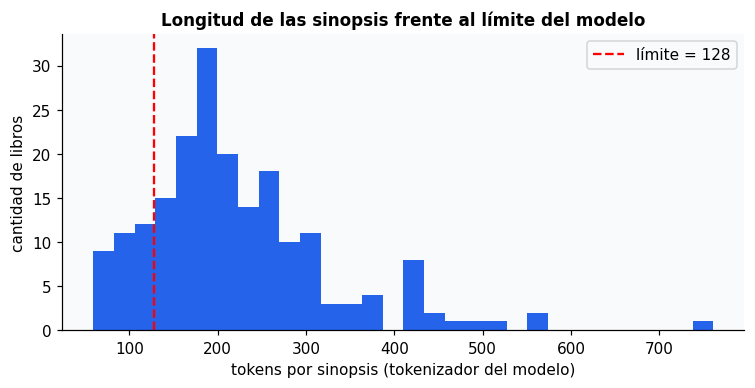


Ejemplo — «Animales difíciles» (761 tokens). El modelo solo lee hasta:
  ... antes, pero cuando los implicados empiezan a desaparecer o a morir el rastro se pierde. La detective y su colega, el inspector Lizard, se verán atrapados en un enigma cada vez más sombrío, en una tram
y descarta el 83% restante.


In [31]:
trunc = informe_truncado(sbert, textos)
n_trunc = trunc["truncado"].sum()
print(f"Sinopsis truncadas: {n_trunc} de {len(textos)} ({n_trunc / len(textos):.0%})")
print(f"Tokens por sinopsis: mediana {trunc['n_tokens'].median():.0f}, máximo {trunc['n_tokens'].max()}")
print(f"Entre las truncadas, fracción de tokens que el modelo NO ve: "
      f"mediana {trunc.loc[trunc.truncado, 'fraccion_perdida'].median():.0%}, "
      f"máxima {trunc['fraccion_perdida'].max():.0%}")

plt.figure(figsize=(8, 3.5))
plt.hist(trunc["n_tokens"], bins=30)
plt.axvline(sbert.max_seq_length, color="red", linestyle="--", label=f"límite = {sbert.max_seq_length}")
plt.xlabel("tokens por sinopsis (tokenizador del modelo)"); plt.ylabel("cantidad de libros")
plt.title("Longitud de las sinopsis frente al límite del modelo"); plt.legend(); plt.show()

# Un ejemplo concreto: dónde se corta la sinopsis más larga
i = int(trunc["n_tokens"].idxmax())
ids = sbert.tokenizer(textos[i], add_special_tokens=True, truncation=False)["input_ids"]
visto = sbert.tokenizer.decode(ids[1:sbert.max_seq_length - 1])
print(f"\nEjemplo — «{df.loc[i, 'titulo']}» ({len(ids)} tokens). El modelo solo lee hasta:")
print("  ...", visto[-200:])
print(f"y descarta el {trunc.loc[i, 'fraccion_perdida']:.0%} restante.")

In [32]:
E_sbert = codificar(sbert, textos)
np.save("emb_sbert_distiluse.npy", E_sbert)
trunc.assign(url_libro=df["url_libro"]).to_csv("truncado_distiluse.csv", index=False)

buscar_sbert = hacer_buscador_st(sbert, E_sbert)
for consulta in ["una novela sobre piratas", "un relato de bucaneros"]:
    idx, sims = buscar_sbert(consulta, 5)
    print(f"\n{consulta}:")
    for j, s in zip(idx, sims):
        print(f"   {s:.3f}  {df.loc[j, 'titulo']}")

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Matriz (200, 512) | no finitos: 0 | normas entre 1.0000 y 1.0000

una novela sobre piratas:
   0.383  El Planeta prodigioso
   0.334  La guerra de los mundos (Ilustrado por Alvim Corrêa)
   0.331  Lo encontrado y lo perdido
   0.306  Radicalizado
   0.294  Un puente sobre el tiempo

un relato de bucaneros:
   0.326  Cuentos futuristas
   0.307  Realidades a medida
   0.268  Meteoritos
   0.255  El guardián de los sueños
   0.251  El general derribó a un ángel


### 5.2. E5

Probamos también E5. Este modelo distingue lo que buscamos de lo que queremos encontrar mediante los prefijos `query:` y `passage:`.

Los agregamos a las consultas y a las sinopsis, respectivamente. También los contamos al medir la longitud, porque ocupan tokens igual que el resto del texto.

In [33]:
NOMBRE_E5 = "intfloat/multilingual-e5-small"
e5 = SentenceTransformer(NOMBRE_E5, device=dispositivo)
print(f"{NOMBRE_E5}: dimensión {e5.get_embedding_dimension()}, límite {e5.max_seq_length} tokens")

trunc_e5 = informe_truncado(e5, textos, prefijo="passage: ")
print(f"Sinopsis truncadas con E5: {trunc_e5['truncado'].sum()} de {len(textos)}")

E_e5 = codificar(e5, textos, prefijo="passage: ")
np.save("emb_e5_small.npy", E_e5)
buscar_e5 = hacer_buscador_st(e5, E_e5, prefijo_consulta="query: ")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (563 > 512). Running this sequence through the model will result in indexing errors


intfloat/multilingual-e5-small: dimensión 384, límite 512 tokens
Sinopsis truncadas con E5: 4 de 200


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Matriz (200, 384) | no finitos: 0 | normas entre 1.0000 y 1.0000


### Resultado: textos truncados

Al comparar, vemos una diferencia grande: Distiluse recorta 168 de las 200 sinopsis, mientras que E5 recorta 4. Por lo tanto, aunque partimos de los mismos textos, no siempre les estamos dando la misma cantidad de información.

Guardamos el detalle para poder revisar qué libros quedan afectados.

In [34]:
tabla_resultados(pd.DataFrame({"Modelo": ["Distiluse", "E5 small"],
    "Dimensiones": [E_sbert.shape[1], E_e5.shape[1]], "Límite de tokens": [sbert.max_seq_length, e5.max_seq_length],
    "Sinopsis truncadas": [int(trunc.truncado.sum()), int(trunc_e5.truncado.sum())],
    "Proporción truncada": [trunc.truncado.mean(), trunc_e5.truncado.mean()]}).set_index("Modelo"),
    "Cuánto texto alcanza a leer cada modelo", formato={"Proporción truncada": "{:.1%}"})
display(Markdown('Al recortar una sinopsis, el modelo puede perder contexto. Lo tenemos en cuenta al comparar las búsquedas.'))

,Dimensiones,Límite de tokens,Sinopsis truncadas,Proporción truncada
Modelo,,,,
Distiluse,512,128,168,84.0%
E5 small,384,512,4,2.0%


Al recortar una sinopsis, el modelo puede perder contexto. Lo tenemos en cuenta al comparar las búsquedas.

<a id="espacios"></a>
## 6. Comparar representaciones

Ya tenemos las distintas representaciones. Ahora hacemos las mismas consultas con todas para comparar los libros que aparecen, y luego miramos cómo se distribuyen los vectores con PCA y t-SNE.

In [35]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 38)

candidatos = [("TF-IDF", "X_tfidf", "buscar_tfidf"),
              ("W2V propio", "E_propio", "buscar_w2v_propio"),
              ("W2V SBW", "E_sbw", "buscar_w2v_sbw"),
              ("SBERT distiluse", "E_sbert", "buscar_sbert"),
              ("E5 small", "E_e5", "buscar_e5")]
MODELOS = {}
for nombre, var_E, var_buscar in candidatos:
    if var_E in globals() and var_buscar in globals():
        E = globals()[var_E]
        E = E.toarray() if hasattr(E, "toarray") else np.asarray(E)   # TF-IDF es dispersa
        normas = np.linalg.norm(E, axis=1, keepdims=True)
        E = np.divide(E, normas, out=np.zeros_like(E, dtype=float), where=normas > 0)
        MODELOS[nombre] = {"E": E, "buscar": globals()[var_buscar]}
print("Modelos a comparar:", {n: m["E"].shape for n, m in MODELOS.items()})

with open("queries.json", encoding="utf-8") as f:
    consultas = {q["id"]: q for q in json.load(f)["consultas"]}
fila_de_url = {u: i for i, u in enumerate(df["url_libro"])}
for q in consultas.values():
    q["rel_idx"] = {fila_de_url[b["url_libro"]] for b in q["relevantes"]}
    q["dud_idx"] = {fila_de_url[b["url_libro"]] for b in q["dudosos"]}

Modelos a comparar: {'TF-IDF': (200, 2181), 'W2V propio': (200, 100), 'W2V SBW': (200, 300), 'SBERT distiluse': (200, 512), 'E5 small': (200, 384)}


### 6.1. Comparar resultados de búsqueda

Ponemos los resultados uno al lado del otro para ver las diferencias sin cambiar de consulta. Las marcas de `queries.json` nos ayudan a leer la tabla: ✔ indica un libro relevante y ? uno dudoso.

In [36]:
def ranking_lado_a_lado(consulta, k=5, rel=frozenset(), dud=frozenset()):
    columnas = {}
    for nombre, m in MODELOS.items():
        idx, sims = m["buscar"](consulta, k)
        marca = lambda i: " ✔" if i in rel else (" ?" if i in dud else "")
        columnas[nombre] = [f"{df.loc[i, 'titulo'][:28]} ({s:.2f}){marca(i)}" for i, s in zip(idx, sims)]
    return pd.DataFrame({n: pd.Series(v, index=range(1, len(v) + 1)) for n, v in columnas.items()}).reindex(range(1, k + 1)).fillna("Sin resultados")

# Elegimos una consulta léxica (q01), las dos sin palabras compartidas (q05, q10)
# y el ejemplo del enunciado, que no está en queries.json.
for qid in ["q01", "q05", "q10"]:
    q = consultas[qid]
    print(f"\n=== [{qid}] {q['consulta']}  ({q['tipo']}) ===")
    print(ranking_lado_a_lado(q["consulta"], rel=q["rel_idx"], dud=q["dud_idx"]).to_string())
print("\n=== una novela sobre piratas (ejemplo del enunciado) ===")
print(ranking_lado_a_lado("una novela sobre piratas").to_string())


=== [q01] historias de viajes en el tiempo y paradojas temporales  (tematica) ===
                               TF-IDF                          W2V propio                           W2V SBW                      SBERT distiluse                            E5 small
1  Un puente sobre el tiempo (0.24) ✔  Un puente sobre el tiempo (0.73) ✔        Cuentos completos (0.78) ?      Pasaporte a la eternidad (0.38)  Un puente sobre el tiempo (0.86) ✔
2               Pansexualactic (0.15)  Náufragos del anti-tiempo (0.68) ?          Saga la Fundación (0.77)           Realidades a medida (0.29)     Pasaporte a la eternidad (0.86)
3          Cuentos completos (0.13) ?          Realidades a medida (0.67)  Noventa millones de soles (0.76)  Poshumanas y distópicas Vol. (0.29)   El volumen del tiempo II (0.85) ✔
4            Saga la Fundación (0.13)          Cuentos completos (0.67) ?   Pasaporte a la eternidad (0.76)  Poshumanas y distópicas Vol. (0.28)    La chica del átomo de oro (0.85)
5          R

En la consulta sobre viajes en el tiempo, E5 encuentra dos libros marcados como relevantes entre los primeros cinco. Para “autómatas con voluntad e identidad”, trae *Protocolo rebelde*, que los otros modelos no ubican en ese top 5.

Estos ejemplos nos permiten ver diferencias concretas; más adelante contamos los aciertos de todas las consultas.

### 6.2. Comparar similitudes

Antes de comparar los puntajes, miramos cómo se distribuyen las similitudes entre libros en cada modelo. Un valor alto no significa lo mismo en todos: nos interesa ver si los vecinos cercanos se distinguen del resto.

                 media  desvío    mín  máx  media top-5 vecinos  contraste (z)
modelo                                                                        
TF-IDF           0.029   0.036  0.000  1.0                0.150          3.370
W2V propio       0.656   0.072  0.309  1.0                0.796          1.934
W2V SBW          0.875   0.050  0.565  1.0                0.937          1.236
SBERT distiluse  0.287   0.104 -0.018  1.0                0.520          2.245
E5 small         0.827   0.021  0.749  1.0                0.873          2.213


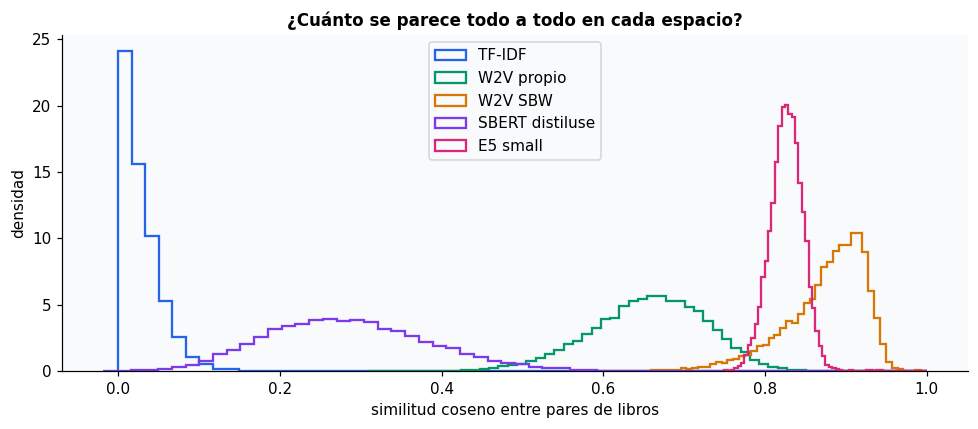

In [37]:
iu = np.triu_indices(len(df), k=1)
filas, sims_por_modelo = [], {}
for nombre, m in MODELOS.items():
    S = m["E"] @ m["E"].T                       # matriz de cosenos (filas normalizadas)
    pares = S[iu]
    sims_por_modelo[nombre] = pares
    S_sin_diag = S.copy(); np.fill_diagonal(S_sin_diag, -np.inf)
    top5 = np.sort(S_sin_diag, axis=1)[:, -5:].mean()   # similitud media con los 5 vecinos más cercanos
    filas.append({"modelo": nombre, "media": pares.mean(), "desvío": pares.std(),
                  "mín": pares.min(), "máx": pares.max(),
                  "media top-5 vecinos": top5,
                  # contraste: a cuántos desvíos del par típico están los vecinos cercanos
                  "contraste (z)": (top5 - pares.mean()) / pares.std()})
dist = pd.DataFrame(filas).set_index("modelo")
print(dist.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for nombre, pares in sims_por_modelo.items():
    ax.hist(pares, bins=60, histtype="step", linewidth=1.5, density=True, label=nombre)
ax.set(xlabel="similitud coseno entre pares de libros", ylabel="densidad",
       title="¿Cuánto se parece todo a todo en cada espacio?")
ax.legend(); plt.tight_layout(); plt.show()

Vemos que E5 y SBW dan similitudes altas incluso a muchos pares de libros. TF-IDF, en cambio, concentra sus valores cerca de cero. Esto explica por qué no conviene leer un 0,8 de un modelo como si significara lo mismo en otro.

También vemos que Distiluse recorta muchas sinopsis: solo lee completas 32 de las 200. Eso nos hace perder parte del texto, pero no alcanza para decir que busca peor que Word2Vec. Para comparar los aciertos miramos después las consultas marcadas como relevantes, en la sección de evaluación.

### 6.3. Elegir colores por género

Para leer los gráficos necesitamos colores. Elegimos un solo género temático por libro, aunque pueda tener varios, y dejamos fuera etiquetas de formato como «Novela» y «Relato».

Esta elección es solo para colorear: no estamos cambiando los géneros originales del libro.

In [38]:
PRIORIDAD = ["Humor", "Distopía", "Juvenil", "Intriga", "Aventuras", "Publicaciónes periódicas", "Fantástico"]
generos = df["generos"].str.split(",").apply(lambda l: [g.strip() for g in l])
df["tema"] = generos.apply(lambda l: next((g for g in PRIORIDAD if g in l), "sin tema específico"))
df["formato"] = generos.apply(lambda l: "Relato" if "Relato" in l else ("Novela" if "Novela" in l else "otro"))
print(df["tema"].value_counts().to_string())

tema
sin tema específico         128
Fantástico                   25
Distopía                     10
Publicaciónes periódicas      9
Aventuras                     9
Juvenil                       7
Humor                         6
Intriga                       6


### 6.4. Revisar los vecinos por género

Nos fijamos en los cinco vecinos de cada libro y contamos cuántos comparten algún género. Comparamos ese valor con elegir vecinos al azar.

También calculamos la silueta para ver qué tan separados quedan los géneros en los vectores originales, antes de dibujarlos en dos dimensiones.

In [39]:
tem = generos.apply(lambda l: {g for g in l if g in PRIORIDAD})
con_tema = np.array([len(t) > 0 for t in tem])
comparte = np.array([[len(tem[i] & tem[j]) > 0 for j in range(len(df))] for i in range(len(df))])
np.fill_diagonal(comparte, False)
piso_vecinos = comparte[con_tema].sum(1).mean() / (len(df) - 1)

filas = []
for nombre, m in MODELOS.items():
    S = m["E"] @ m["E"].T; np.fill_diagonal(S, -np.inf)
    vecinos = np.argsort(-S, axis=1)[:, :5]
    acuerdo = np.mean([comparte[i, vecinos[i]].mean() for i in np.where(con_tema)[0]])
    sil = silhouette_score(m["E"][con_tema], df["tema"][con_tema], metric="cosine")
    filas.append({"modelo": nombre, "acuerdo vecinos@5": acuerdo, "silueta (coseno)": sil})
estructura = pd.DataFrame(filas).set_index("modelo")
print(f"Piso de azar para el acuerdo de vecinos: {piso_vecinos:.3f}")
print(estructura.round(3).to_string())

Piso de azar para el acuerdo de vecinos: 0.110
                 acuerdo vecinos@5  silueta (coseno)
modelo                                              
TF-IDF                       0.411             0.088
W2V propio                   0.378             0.060
W2V SBW                      0.364            -0.027
SBERT distiluse              0.386             0.067
E5 small                     0.422             0.077


### 6.5. Dibujar los vectores

Ahora dibujamos los vectores. Con PCA conservamos las dos direcciones de mayor variación; con t-SNE buscamos ver mejor los vecinos cercanos.

Al leer los mapas, recordamos que estamos simplificando muchas dimensiones en solo dos. En particular, la distancia entre grupos de t-SNE no nos dice directamente cuánto se parecen en el espacio original.

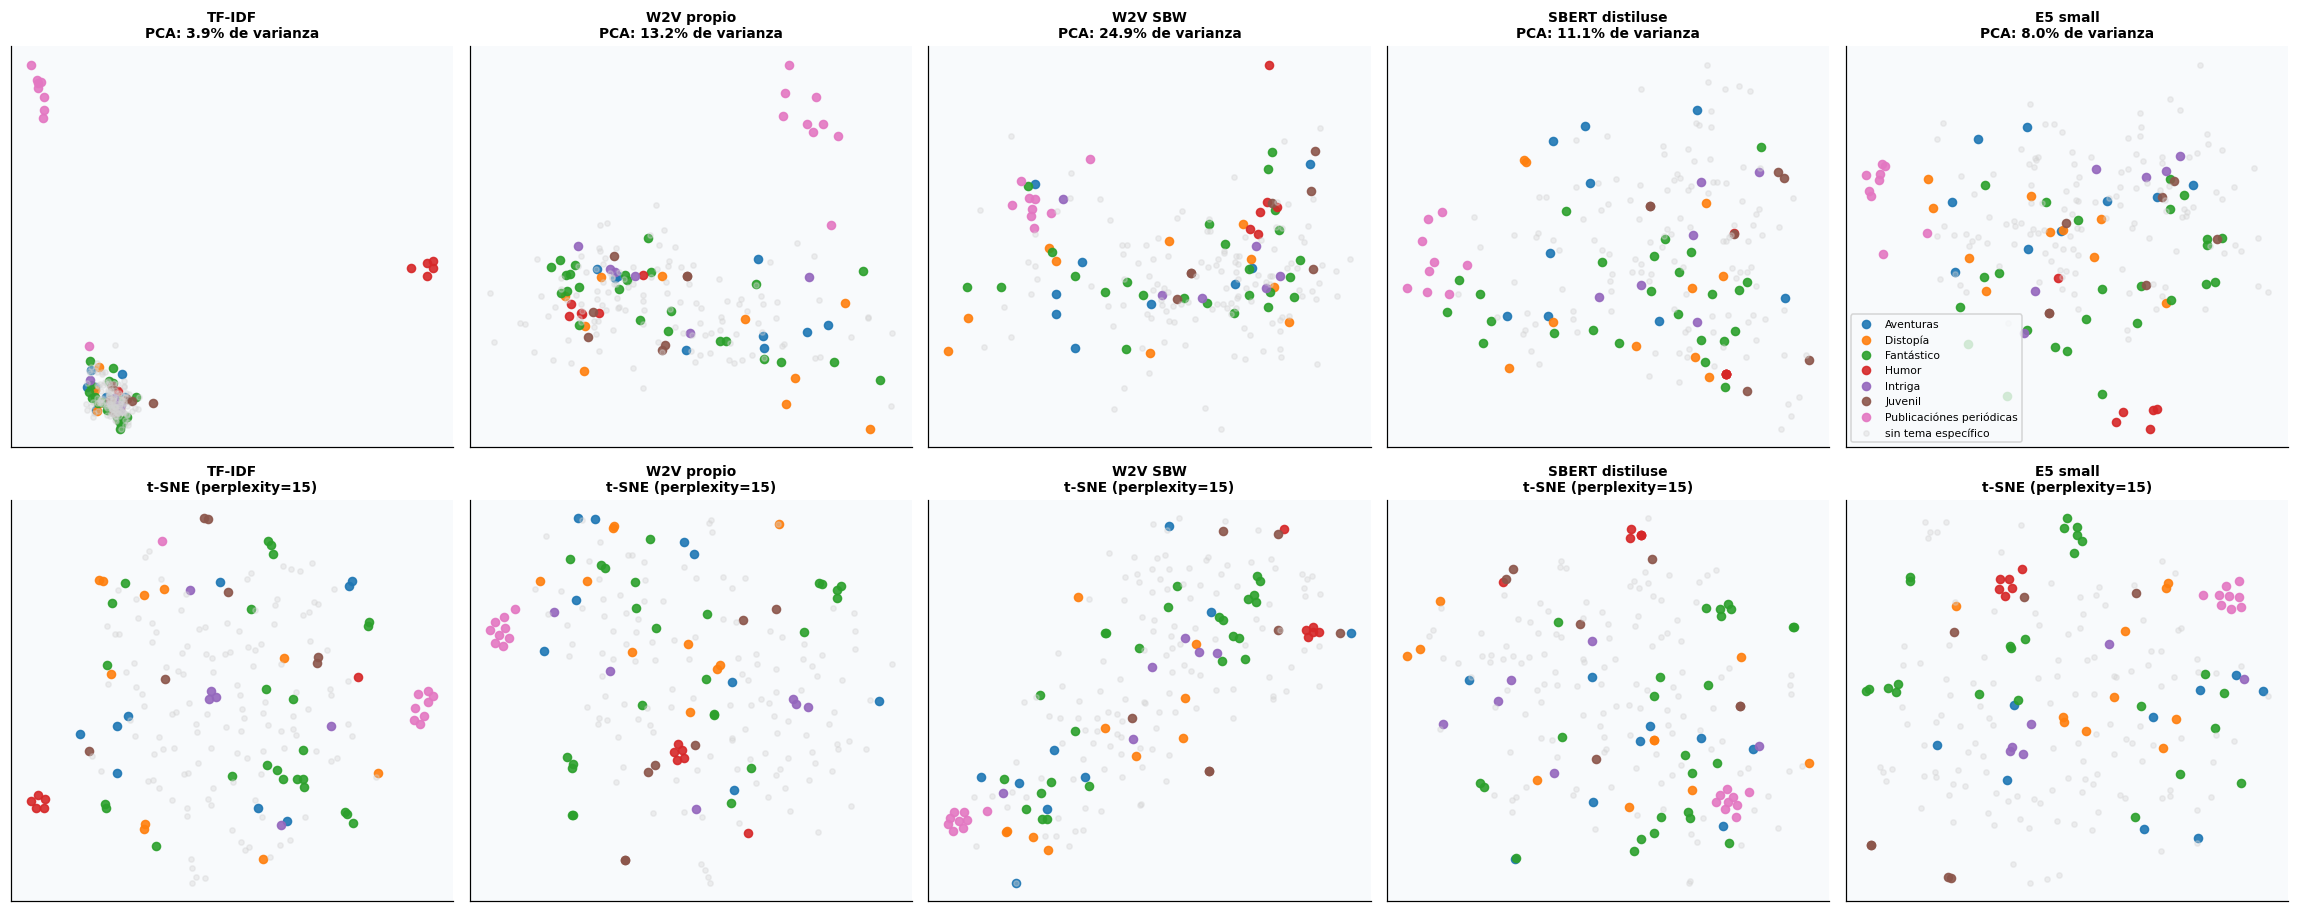

Varianza explicada por las 2 primeras componentes principales:
  TF-IDF           3.9%  (se descarta el 96.1%)
  W2V propio       13.2%  (se descarta el 86.8%)
  W2V SBW          24.9%  (se descarta el 75.1%)
  SBERT distiluse  11.1%  (se descarta el 88.9%)
  E5 small         8.0%  (se descarta el 92.0%)


In [40]:
PERPLEXITY = 15
temas = sorted(df["tema"].unique(), key=lambda t: (t == "sin tema específico", t))
colores = dict(zip(temas, plt.cm.tab10.colors))

fig, axes = plt.subplots(2, len(MODELOS), figsize=(4.2 * len(MODELOS), 8.4), squeeze=False)
varianza = {}
for c, (nombre, m) in enumerate(MODELOS.items()):
    pca = PCA(n_components=2, random_state=0)
    P = pca.fit_transform(m["E"])
    varianza[nombre] = pca.explained_variance_ratio_.sum()
    T = TSNE(n_components=2, perplexity=PERPLEXITY, metric="cosine", init="pca",
             random_state=0).fit_transform(m["E"])
    for fila, (Y, titulo) in enumerate([(P, f"{nombre}\nPCA: {varianza[nombre]:.1%} de varianza"),
                                        (T, f"{nombre}\nt-SNE (perplexity={PERPLEXITY})")]):
        ax = axes[fila, c]
        for t in temas:
            sel = (df["tema"] == t).to_numpy()
            gris = t == "sin tema específico"
            ax.scatter(Y[sel, 0], Y[sel, 1], s=12 if gris else 28, alpha=0.35 if gris else 0.9,
                       color="lightgray" if gris else colores[t], label=t)
        ax.set_title(titulo, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
axes[0, -1].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()

print("Varianza explicada por las 2 primeras componentes principales:")
for nombre, v in varianza.items():
    print(f"  {nombre:<16} {v:.1%}  (se descarta el {1 - v:.1%})")

In [41]:
tabla_resultados(pd.Series(varianza, name="Varianza conservada en 2D"), "PCA: información retenida", formato={"Varianza conservada en 2D": "{:.1%}"})

,Varianza conservada en 2D
TF-IDF,3.9%
W2V propio,13.2%
W2V SBW,24.9%
SBERT distiluse,11.1%
E5 small,8.0%


Las dos primeras componentes de PCA conservan entre el 3,9 % y el 24,9 % de la variación, según el modelo. Queda bastante información fuera del dibujo, así que usamos estos mapas para orientarnos y los acompañamos con las medidas calculadas sobre los vectores completos.

<a id="persistencia"></a>
## 7. Guardar en PostgreSQL

Hasta ahora buscamos en memoria con Python. Guardamos los libros y sus vectores en PostgreSQL para poder hacer lo mismo desde SQL.

Usamos el esquema `pln_tp2_local` y una tabla por modelo. Al ejecutar este bloque actualizamos los datos de los libros y recreamos las cuatro tablas de embeddings.

In [42]:
import numpy as np
import pandas as pd
import psycopg
from psycopg import sql
from pgvector.psycopg import register_vector

conn = abrir_conexion_supabase(crear_esquema=True)
version = conn.execute("SELECT extversion FROM pg_extension WHERE extname = 'vector';").fetchone()[0]
print(f"Conectado al esquema {DB_SCHEMA}. pgvector {version}")

Conectado al esquema pln_tp2_local. pgvector 0.8.2


### 7.1. Seleccionar los modelos

El ejercicio nos pide guardar representaciones de familias distintas. Como ya calculamos los vectores de palabras y los de oraciones, aprovechamos y guardamos los cuatro modelos disponibles.

In [43]:
CARPETA = globals().get("CARPETA", "")
MODELOS = [  # (tabla, variable en memoria, archivo .npy, familia)
    ("emb_w2v_propio", "E_propio", "emb_w2v_propio.npy",      "promedio de word vectors"),
    ("emb_w2v_sbw",    "E_sbw",    "emb_w2v_sbw.npy",         "promedio de word vectors"),
    ("emb_sbert",      "E_sbert",  "emb_sbert_distiluse.npy", "modelo de oración"),
    ("emb_e5",         "E_e5",     "emb_e5_small.npy",        "modelo de oración"),
]
A_GUARDAR = {}
for tabla, var, archivo, familia in MODELOS:
    if var in globals():
        A_GUARDAR[tabla] = (np.asarray(globals()[var]), familia)
    elif os.path.exists(CARPETA + archivo):
        A_GUARDAR[tabla] = (np.load(CARPETA + archivo), familia)

for tabla, (E, familia) in A_GUARDAR.items():
    print(f"{tabla:<16} {E.shape}  ({familia})")
assert len({f for _, f in A_GUARDAR.values()}) == 2, "Falta una de las dos familias de embeddings"

emb_w2v_propio   (200, 100)  (promedio de word vectors)
emb_w2v_sbw      (200, 300)  (promedio de word vectors)
emb_sbert        (200, 512)  (modelo de oración)
emb_e5           (200, 384)  (modelo de oración)


### 7.2. Validar los vectores

Antes de insertar, comprobamos que los vectores tengan valores finitos y una norma distinta de cero. Un vector con NaN, infinito o todos ceros no nos serviría para calcular la distancia coseno.

Normalizamos los que pasan el control y contamos cuántos podemos guardar.

In [44]:
def validar(E, tabla):
    E = np.asarray(E, dtype=np.float64)
    assert E.shape[0] == len(df), f"{tabla}: {E.shape[0]} filas, pero df tiene {len(df)}"
    finito = np.isfinite(E).all(axis=1)
    normas = np.linalg.norm(np.where(np.isfinite(E), E, 0.0), axis=1)
    valido = finito & (normas > 1e-8)
    E_ok = np.zeros(E.shape, dtype=np.float32)
    E_ok[valido] = (E[valido] / normas[valido, None]).astype(np.float32)
    print(f"{tabla:<16} válidos: {valido.sum()}/{len(valido)} | con NaN/inf: {(~finito).sum()} | "
          f"vector cero: {(finito & (normas <= 1e-8)).sum()}")
    for i in np.where(~valido)[0]:
        print(f"   excluido: {df.loc[i, 'titulo']}")
    return E_ok, valido

VALIDADOS = {tabla: validar(E, tabla) for tabla, (E, _) in A_GUARDAR.items()}

emb_w2v_propio   válidos: 200/200 | con NaN/inf: 0 | vector cero: 0
emb_w2v_sbw      válidos: 200/200 | con NaN/inf: 0 | vector cero: 0
emb_sbert        válidos: 200/200 | con NaN/inf: 0 | vector cero: 0
emb_e5           válidos: 200/200 | con NaN/inf: 0 | vector cero: 0


In [45]:
conn.execute("""
    CREATE TABLE IF NOT EXISTS books (
        id         serial PRIMARY KEY,
        url_libro  text UNIQUE NOT NULL,
        titulo     text NOT NULL,
        autores    text,
        generos    text[] NOT NULL,
        serie      text,
        sinopsis   text NOT NULL
    );
""")
filas_books = [(r.url_libro, r.titulo, r.autores,
                [g.strip() for g in r.generos.split(",")],
                None if pd.isna(r.serie) else r.serie, r.sinopsis)
               for r in df.itertuples()]
with conn.transaction():
    conn.cursor().executemany("""
        INSERT INTO books (url_libro, titulo, autores, generos, serie, sinopsis)
        VALUES (%s, %s, %s, %s, %s, %s)
        ON CONFLICT (url_libro) DO UPDATE SET
            titulo = EXCLUDED.titulo, autores = EXCLUDED.autores, generos = EXCLUDED.generos,
            serie = EXCLUDED.serie, sinopsis = EXCLUDED.sinopsis;
    """, filas_books)
conn.execute("CREATE INDEX IF NOT EXISTS books_generos_idx ON books USING gin (generos);")

# Supabase publica las tablas de 'public' por su API REST: con RLS activado y sin políticas,
# esa API no expone nada. La conexión como 'postgres' (la nuestra) no se ve afectada.
conn.execute("ALTER TABLE books ENABLE ROW LEVEL SECURITY;")

id_de_url = dict(conn.execute("SELECT url_libro, id FROM books;").fetchall())
book_ids = df["url_libro"].map(id_de_url).to_numpy()
print(f"books: {conn.execute('SELECT count(*) FROM books').fetchone()[0]} filas")

books: 200 filas


### 7.3. Crear las tablas e insertar

Creamos cada tabla con la dimensión que corresponde a su modelo mediante `vector(n)`. Agregamos un `CHECK` para comprobar que los vectores estén normalizados.

Después probamos una inserción con la dimensión equivocada para verificar que PostgreSQL la rechace.

In [46]:
for tabla, (E_ok, valido) in VALIDADOS.items():
    dim = E_ok.shape[1]
    t = sql.Identifier(tabla)
    conn.execute(sql.SQL("DROP TABLE IF EXISTS {};").format(sql.Identifier(DB_SCHEMA, tabla)))   # se recrea en cada corrida
    conn.execute(sql.SQL("""
        CREATE TABLE {t} (
            book_id   int PRIMARY KEY REFERENCES books(id) ON DELETE CASCADE,
            embedding vector({dim}) NOT NULL,
            CONSTRAINT {chk} CHECK (abs(vector_norm(embedding) - 1) < 1e-3)
        );""").format(t=t, dim=sql.Literal(dim), chk=sql.Identifier(f"{tabla}_normalizado")))
    filas = [(int(book_ids[i]), E_ok[i]) for i in np.where(valido)[0]]
    with conn.transaction():                                 # todo o nada
        conn.cursor().executemany(
            sql.SQL("INSERT INTO {} (book_id, embedding) VALUES (%s, %s);").format(t), filas)
    conn.execute(sql.SQL("ALTER TABLE {} ENABLE ROW LEVEL SECURITY;").format(t))
    print(f"{tabla:<16} vector({dim}): {len(filas)} filas insertadas")

emb_w2v_propio   vector(100): 200 filas insertadas
emb_w2v_sbw      vector(300): 200 filas insertadas
emb_sbert        vector(512): 200 filas insertadas
emb_e5           vector(384): 200 filas insertadas


In [47]:
tabla_chica, (E_chica, _) = min(VALIDADOS.items(), key=lambda kv: kv[1][0].shape[1])
tabla_grande = max(VALIDADOS, key=lambda k: VALIDADOS[k][0].shape[1])
try:
    with conn.transaction():
        conn.execute(sql.SQL("INSERT INTO {} (book_id, embedding) VALUES (%s, %s);")
                     .format(sql.Identifier(tabla_grande)), (int(book_ids[0]), E_chica[0]))
except psycopg.Error as e:
    print(f"Insertar un vector de {E_chica.shape[1]} dimensiones en {tabla_grande}: "
          f"{e.diag.message_primary}")

Insertar un vector de 100 dimensiones en emb_sbert: expected 512 dimensions, not 100


Los cuatro modelos pasan el control y guardamos 200 vectores en cada tabla. La inserción de prueba falla porque intentamos poner un vector de 100 dimensiones en una columna que espera 512. Eso es lo que queríamos comprobar: no podemos mezclar dimensiones por accidente.

### 7.4. Crear y comprobar los índices

Agregamos índices HNSW para buscar vecinos por distancia coseno. Usamos `vector_cosine_ops` al crear el índice y `<=>` al consultar, de modo que ambos trabajen con la misma distancia.

Comparamos los resultados de SQL con los de NumPy y miramos el plan de ejecución. Como solo tenemos 200 libros, PostgreSQL puede decidir que le conviene recorrer la tabla completa.

In [48]:
for tabla in VALIDADOS:
    conn.execute(sql.SQL("""
        CREATE INDEX IF NOT EXISTS {idx} ON {t} USING hnsw (embedding vector_cosine_ops)
        WITH (m = 16, ef_construction = 64);""").format(
        idx=sql.Identifier(f"{tabla}_hnsw"), t=sql.Identifier(tabla)))
indices = conn.execute("""
    SELECT tablename, indexname, indexdef FROM pg_indexes
    WHERE schemaname = current_schema() AND tablename = ANY(%s)
      AND indexdef ILIKE %s ORDER BY tablename;""", (list(VALIDADOS), "%hnsw%")).fetchall()
for tabla, nombre, definicion in indices:
    print(f"{nombre}:\n   {definicion}")

emb_e5_hnsw:
   CREATE INDEX emb_e5_hnsw ON pln_tp2_local.emb_e5 USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')
emb_sbert_hnsw:
   CREATE INDEX emb_sbert_hnsw ON pln_tp2_local.emb_sbert USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')
emb_w2v_propio_hnsw:
   CREATE INDEX emb_w2v_propio_hnsw ON pln_tp2_local.emb_w2v_propio USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')
emb_w2v_sbw_hnsw:
   CREATE INDEX emb_w2v_sbw_hnsw ON pln_tp2_local.emb_w2v_sbw USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')


In [49]:
filas = []
for tabla in VALIDADOS:
    r = conn.execute(sql.SQL("""
        SELECT count(*), count(*) FILTER (WHERE embedding IS NULL),
               min(vector_dims(embedding)), max(vector_dims(embedding)),
               min(vector_norm(embedding)), max(vector_norm(embedding))
        FROM {};""").format(sql.Identifier(tabla))).fetchone()
    filas.append(dict(zip(["tabla", "filas", "nulos", "dim mín", "dim máx", "norma mín", "norma máx"],
                          (tabla,) + r)))
display(pd.DataFrame(filas).set_index("tabla").round(5))

# La búsqueda en SQL tiene que dar lo mismo que en numpy (sobre los mismos vectores)
tabla = list(VALIDADOS)[-1]
E_ok, valido = VALIDADOS[tabla]
i = 0
filas_sql = conn.execute(sql.SQL("""
    SELECT b.titulo, 1 - (e.embedding <=> %s) AS similitud
    FROM {} e JOIN books b ON b.id = e.book_id
    ORDER BY e.embedding <=> %s LIMIT 5;""").format(sql.Identifier(tabla)),
    (E_ok[i], E_ok[i])).fetchall()
sims_np = E_ok @ E_ok[i]
sims_np[~valido] = -np.inf
top_np = np.argsort(-sims_np)[:5]
comparacion = pd.DataFrame({"SQL": [f"{t} ({s:.3f})" for t, s in filas_sql],
                            "numpy": [f"{df.loc[j, 'titulo']} ({sims_np[j]:.3f})" for j in top_np]},
                           index=range(1, 6))
print(f"\nVecinos de «{df.loc[i, 'titulo']}» en {tabla} (el 1.º es el propio libro):")
display(comparacion)

,filas,nulos,dim mín,dim máx,norma mín,norma máx
tabla,,,,,,
emb_w2v_propio,200,0,100,100,1.0,1.0
emb_w2v_sbw,200,0,300,300,1.0,1.0
emb_sbert,200,0,512,512,1.0,1.0
emb_e5,200,0,384,384,1.0,1.0



Vecinos de «Más Allá 23» en emb_e5 (el 1.º es el propio libro):


,SQL,numpy
1,Más Allá 23 (1.000),Más Allá 23 (1.000)
2,Más Allá 22 (0.948),Más Allá 22 (0.948)
3,Más Allá 21 (0.942),Más Allá 21 (0.942)
4,Más Allá 17 (0.939),Más Allá 17 (0.939)
5,Más Allá 15 (0.934),Más Allá 15 (0.934)


In [50]:
import re
consulta_cos = sql.SQL("SELECT book_id FROM {} ORDER BY embedding <=> %s LIMIT 5;").format(sql.Identifier(tabla))
consulta_l2 = sql.SQL("SELECT book_id FROM {} ORDER BY embedding <-> %s LIMIT 5;").format(sql.Identifier(tabla))

def plan(consulta, forzar_indice=False):
    with conn.transaction():
        if forzar_indice:
            conn.execute("SET LOCAL enable_seqscan = off;")
        filas = conn.execute(sql.SQL("EXPLAIN ") + consulta, (E_ok[i],)).fetchall()
    lineas = [re.sub(r"'\[[^\]]*\]'::vector", "'[…vector…]'", f[0]) for f in filas]
    return "\n   ".join(l for l in lineas if not l.strip().startswith(("JIT", "Functions", "Options")))

print("1) Plan normal con <=> (200 filas: recorrer la tabla es más barato que el índice):\n  ", plan(consulta_cos))
print("\n2) Desalentando el recorrido secuencial, con <=> (coincide con vector_cosine_ops):\n  ", plan(consulta_cos, True))
print("\n3) Igual, pero con <-> (euclídea, NO coincide con la opclass): el índice no se puede usar\n  ", plan(consulta_l2, True))

1) Plan normal con <=> (200 filas: recorrer la tabla es más barato que el índice):
   Limit  (cost=45.82..45.83 rows=5 width=12)
     ->  Sort  (cost=45.82..46.32 rows=200 width=12)
           Sort Key: ((embedding <=> '[…vector…]'))
           ->  Seq Scan on emb_e5  (cost=0.00..42.50 rows=200 width=12)

2) Desalentando el recorrido secuencial, con <=> (coincide con vector_cosine_ops):
   Limit  (cost=57.60..58.76 rows=5 width=12)
     ->  Index Scan using emb_e5_hnsw on emb_e5  (cost=57.60..104.10 rows=200 width=12)
           Order By: (embedding <=> '[…vector…]')

3) Igual, pero con <-> (euclídea, NO coincide con la opclass): el índice no se puede usar
   Limit  (cost=10000000045.82..10000000045.83 rows=5 width=12)
     ->  Sort  (cost=10000000045.82..10000000046.32 rows=200 width=12)
           Sort Key: ((embedding <-> '[…vector…]'))
           ->  Seq Scan on emb_e5  (cost=10000000000.00..10000000042.50 rows=200 width=12)


SQL y NumPy devuelven los mismos vecinos para el ejemplo. En el plan habitual aparece un recorrido completo de la tabla; al desalentarlo, vemos que PostgreSQL sí puede usar el índice HNSW con `<=>`.

Cuando cambiamos a la distancia euclídea (`<->`), ese índice deja de servir para ordenar la consulta, porque lo creamos para coseno.

<a id="sql"></a>
## 8. Buscar con filtros

Ya podemos buscar desde SQL. Convertimos la consulta en un vector con el mismo modelo que usamos para los libros y pedimos los más cercanos.

Después agregamos filtros por género: primero uno solo y luego dos a la vez, para comprobar que los resultados cumplan ambas condiciones.

In [51]:
import json
import numpy as np
import pandas as pd
import psycopg
from psycopg import sql
from pgvector.psycopg import register_vector

if "conn" not in globals() or conn.closed:
    conn = abrir_conexion_supabase()

version = conn.execute("SELECT extversion FROM pg_extension WHERE extname = 'vector';").fetchone()[0]
print(f"pgvector {version}")

generos_db = pd.DataFrame(conn.execute("""
    SELECT g AS genero, count(*) AS libros
    FROM books, unnest(generos) AS g GROUP BY g ORDER BY libros DESC;""").fetchall(),
    columns=["genero", "libros"])
display(generos_db.head(12))

pgvector 0.8.2


,genero,libros
0,Ciencia ficción,200
1,Novela,161
2,Relato,39
3,Fantástico,36
4,Distopía,10
5,Aventuras,10
6,Publicaciónes periódicas,9
7,Juvenil,8
8,Intriga,8
9,Humor,6


In [52]:
CODIFICADORES = {}
if "e5" in globals():
    CODIFICADORES["emb_e5"] = lambda c: e5.encode("query: " + c, normalize_embeddings=True)
if "sbert" in globals():
    CODIFICADORES["emb_sbert"] = lambda c: sbert.encode(c, normalize_embeddings=True)
if "kv_sbw" in globals():
    CODIFICADORES["emb_w2v_sbw"] = lambda c: vector_documento(tokenizar(c), kv_sbw, en_sbw)[0]
if "kv_propio" in globals():
    CODIFICADORES["emb_w2v_propio"] = lambda c: vector_documento(tokenizar(c), kv_propio)[0]
MODELO_POR_DEFECTO = next(m for m in ["emb_e5", "emb_sbert", "emb_w2v_sbw", "emb_w2v_propio"] if m in CODIFICADORES)
print("Modelos disponibles para buscar:", list(CODIFICADORES), "| por defecto:", MODELO_POR_DEFECTO)

Modelos disponibles para buscar: ['emb_e5', 'emb_sbert', 'emb_w2v_sbw', 'emb_w2v_propio'] | por defecto: emb_e5


In [53]:
def buscar(consulta, k=5, genero=None, modelo=None, *,
           forzar_indice=False, ef_search=None, iterativo=None, exacto=False, avisar=True):
    """Devuelve los k libros más similares a la consulta, opcionalmente filtrando por género.

    consulta : texto en lenguaje natural
    genero   : None, un género ("Humor") o una lista (["Novela", "Distopía"] = debe tener TODOS)
    modelo   : tabla de embeddings a usar (por defecto, MODELO_POR_DEFECTO)
    Parámetros del experimento de recall (bloque 5; para el uso normal no hacen falta):
      forzar_indice : obliga a usar el índice HNSW (desactiva los planes alternativos: recorrer
                      la tabla, ordenar después, o resolver el join de otra forma)
      ef_search     : candidatos que explora el índice (pgvector usa 40 por defecto)
      iterativo     : 'relaxed_order' o 'strict_order' = escaneo iterativo (pgvector >= 0.8)
      exacto        : prohíbe el índice HNSW = búsqueda exacta (referencia para medir recall)
    """
    modelo = modelo or MODELO_POR_DEFECTO
    q = np.asarray(CODIFICADORES[modelo](consulta), dtype=np.float32)
    columnas = ["book_id", "titulo", "generos", "similitud"]
    if not np.isfinite(q).all() or np.linalg.norm(q) == 0:
        # Pasa con Word2Vec si ninguna palabra de la consulta está en su vocabulario:
        # la distancia coseno a un vector cero no está definida.
        if avisar:
            print(f"[{modelo}] la consulta no tiene representación (vector cero): sin resultados")
        return pd.DataFrame(columns=columnas)

    params = {"q": q, "k": k}
    filtro = sql.SQL("")
    if genero:
        params["generos"] = [genero] if isinstance(genero, str) else list(genero)
        # ids de los libros que tienen TODOS esos géneros (@> = "contiene")
        filtro = sql.SQL("WHERE book_id = ANY(ARRAY(SELECT id FROM books WHERE generos @> %(generos)s::text[]))")

    # Subconsulta interna: los k vectores más cercanos (acá actúa el índice HNSW y el filtro).
    # Consulta externa: agrega título y géneros de esos k libros.
    consulta_sql = sql.SQL("""
        SELECT b.id, b.titulo, b.generos, 1 - e.distancia AS similitud
        FROM (
            SELECT book_id, embedding <=> %(q)s AS distancia
            FROM {tabla}
            {filtro}
            ORDER BY embedding <=> %(q)s
            LIMIT %(k)s
        ) e
        JOIN books b ON b.id = e.book_id
        ORDER BY e.distancia;""").format(tabla=sql.Identifier(modelo), filtro=filtro)

    with conn.transaction():          # los SET LOCAL valen solo dentro de esta transacción
        ajustes = {}
        if forzar_indice:
            ajustes.update({k: "off" for k in ("enable_seqscan", "enable_bitmapscan", "enable_sort",
                                               "enable_mergejoin", "enable_hashjoin")})
        if exacto:
            ajustes["enable_indexscan"] = "off"
        if ef_search:
            ajustes["hnsw.ef_search"] = str(ef_search)
        if iterativo:
            ajustes["hnsw.iterative_scan"] = iterativo
        for nombre, valor in ajustes.items():
            conn.execute("SELECT set_config(%s, %s, true);", (nombre, valor))
        filas = conn.execute(consulta_sql, params).fetchall()
    return pd.DataFrame(filas, columns=columnas)

In [54]:
print("Sin filtro:")
display(buscar("viajes en el tiempo", k=5))
print("Con filtro de un género:")
display(buscar("una historia divertida en el espacio", k=5, genero="Humor"))
print("Con filtro de dos géneros a la vez (debe tener ambos):")
display(buscar("una sociedad que controla a sus ciudadanos", k=5, genero=["Novela", "Distopía"]))

Sin filtro:


,book_id,titulo,generos,similitud
0,131,Un puente sobre el tiempo,"[Ciencia ficción, Novela]",0.865181
1,115,El volumen del tiempo II,"[Ciencia ficción, Novela]",0.855252
2,132,Yo viví en el año 3000,"[Ciencia ficción, Novela]",0.852827
3,48,Más Allá 20,"[Ciencia ficción, Fantástico, Publ...",0.852324
4,104,La chica del átomo de oro,"[Ciencia ficción, Relato]",0.851893


Con filtro de un género:


,book_id,titulo,generos,similitud
0,165,La gran cruzada,"[Ciencia ficción, Humor, Novela]",0.832183
1,99,"Bill, el héroe galáctico en el pla...","[Ciencia ficción, Humor, Novela]",0.827273
2,102,"Bill, el héroe galáctico en el pla...","[Ciencia ficción, Humor, Novela]",0.824707
3,83,"Bill, el héroe galáctico. ¡El fina...","[Ciencia ficción, Humor, Novela]",0.821129
4,94,"Bill, el héroe galáctico en el pla...","[Ciencia ficción, Humor, Novela]",0.813205


Con filtro de dos géneros a la vez (debe tener ambos):


,book_id,titulo,generos,similitud
0,52,Ahora todo es mejor,"[Ciencia ficción, Distopía, Novela]",0.842969
1,65,Inmanencia,"[Ciencia ficción, Distopía, Intrig...",0.830921
2,86,Multiverso,"[Ciencia ficción, Distopía, Intrig...",0.816420
3,130,Balada de pájaros cantores y serpi...,"[Ciencia ficción, Distopía, Juveni...",0.816213
4,141,1984 (Ilustrado),"[Ciencia ficción, Distopía, Novela]",0.806091


In [55]:
fila_de_url_actual = {url: i for i, url in enumerate(df["url_libro"])}
fila_de_book_id = {bid: fila_de_url_actual[url]
                   for bid, url in conn.execute("SELECT id, url_libro FROM books;").fetchall()
                   if url in fila_de_url_actual}

def hacer_buscador_sql(modelo):
    def buscador(consulta, k):
        r = buscar(consulta, k, modelo=modelo)
        return [fila_de_book_id[b] for b in r["book_id"]], list(r["similitud"])
    return buscador

# Control: la búsqueda en SQL tiene que coincidir con la búsqueda en numpy de la Parte C/D
consulta_control = "autómatas con voluntad e identidad"
buscador_python = {"emb_e5": "buscar_e5", "emb_sbert": "buscar_sbert",
                   "emb_w2v_sbw": "buscar_w2v_sbw", "emb_w2v_propio": "buscar_w2v_propio"}[MODELO_POR_DEFECTO]
if buscador_python in globals():
    idx_sql, _ = hacer_buscador_sql(MODELO_POR_DEFECTO)(consulta_control, 5)
    idx_py, _ = globals()[buscador_python](consulta_control, 5)
    print(f"SQL y Python devuelven los mismos 5 libros, en el mismo orden: {list(idx_sql) == list(idx_py)}")

SQL y Python devuelven los mismos 5 libros, en el mismo orden: True


### 8.1. Comprobar filtros con HNSW

Al filtrar, podemos encontrarnos con menos de `k` resultados: algunos candidatos del índice se descartan por no pertenecer al género pedido.

Probamos aumentar `ef_search` y usar el escaneo iterativo. Los comparamos con una búsqueda exacta para ver si recuperamos los libros que faltaban.

In [56]:
with open("queries.json", encoding="utf-8") as f:
    textos_consulta = [q["consulta"] for q in json.load(f)["consultas"]]

K = 5
CONFIGURACIONES = {
    "índice, ef_search=40 (defecto)": dict(forzar_indice=True),
    "índice, ef_search=200":          dict(forzar_indice=True, ef_search=200),
    "índice + escaneo iterativo":     dict(forzar_indice=True, iterativo="relaxed_order"),
}
GENEROS_PRUEBA = ["Humor", "Intriga", "Distopía", "Fantástico", "Novela"]
libros_por_genero = dict(zip(generos_db["genero"], generos_db["libros"]))

filas = []
for g in GENEROS_PRUEBA:
    for c in textos_consulta:
        exacto = set(buscar(c, K, genero=g, exacto=True, avisar=False)["book_id"])
        if not exacto:      # la consulta no tiene representación en este modelo: no se puede medir
            continue
        for nombre, cfg in CONFIGURACIONES.items():
            aprox = set(buscar(c, K, genero=g, avisar=False, **cfg)["book_id"])
            filas.append({"género": f"{g} ({libros_por_genero.get(g, 0)} libros)", "configuración": nombre,
                          "resultados devueltos": len(aprox),
                          "recall@k": len(aprox & exacto) / len(exacto)})
recall = (pd.DataFrame(filas)
          .pivot_table(index="género", columns="configuración", values=["resultados devueltos", "recall@k"],
                       aggfunc="mean", sort=False))
print(f"Promedio sobre {len(textos_consulta)} consultas, k = {K}. La búsqueda exacta es la referencia (recall = 1).")
display(recall.round(2))

Promedio sobre 10 consultas, k = 5. La búsqueda exacta es la referencia (recall = 1).


resultados devueltos                                                                        recall@k                                                 
configuración          índice, ef_search=40 (defecto) índice, ef_search=200 índice + escaneo iterativo índice, ef_search=40 (defecto) índice, ef_search=200 índice + escaneo iterativo
género                                                                                                                                                                                
Humor (6 libros)                                  1.7                   5.0                        5.0                           0.34                   1.0                        1.0
Intriga (8 libros)                                2.5                   5.0                        5.0                           0.50                   1.0                        1.0
Distopía (10 libros)                              2.5                   5.0                        5.0                           0.50                   1.0                        1.0
Fantástico (36 libros)                            3.6                   5.0                        5.0                           0.72                   1.0                        1.0
Novela (161 libros)                               5.0                   5.0                        5.0                           1.00                   1.0                        1.0

In [57]:
def plan_real(consulta, genero, **cfg):
    q = np.asarray(CODIFICADORES[MODELO_POR_DEFECTO](consulta), dtype=np.float32)
    consulta_sql = sql.SQL("""
        EXPLAIN (ANALYZE, COSTS OFF, TIMING OFF, SUMMARY OFF)
        SELECT book_id FROM {t}
        WHERE book_id = ANY(ARRAY(SELECT id FROM books WHERE generos @> %(g)s::text[]))
        ORDER BY embedding <=> %(q)s LIMIT 5;""").format(t=sql.Identifier(MODELO_POR_DEFECTO))
    with conn.transaction():
        for k in ("enable_seqscan", "enable_bitmapscan", "enable_sort", "enable_mergejoin", "enable_hashjoin"):
            conn.execute("SELECT set_config(%s, 'off', true);", (k,))
        if cfg.get("iterativo"):
            conn.execute("SELECT set_config('hnsw.iterative_scan', %s, true);", (cfg["iterativo"],))
        lineas = [f[0] for f in conn.execute(consulta_sql, {"q": q, "g": [genero]}).fetchall()]
    return "\n   ".join(l for l in lineas if "vector" not in l or "Index" in l)

print("Índice HNSW + filtro Humor, configuración por defecto:\n  ", plan_real(textos_consulta[0], "Humor"))
print("\nLo mismo con escaneo iterativo:\n  ", plan_real(textos_consulta[0], "Humor", iterativo="relaxed_order"))

Índice HNSW + filtro Humor, configuración por defecto:
   Limit (actual rows=1 loops=1)
     InitPlan 1
       ->  Bitmap Heap Scan on books (actual rows=6 loops=1)
             Recheck Cond: (generos @> '{Humor}'::text[])
             Heap Blocks: exact=5
             ->  Bitmap Index Scan on books_generos_idx (actual rows=6 loops=1)
                   Index Cond: (generos @> '{Humor}'::text[])
     ->  Index Scan using emb_e5_hnsw on emb_e5 (actual rows=1 loops=1)
           Filter: (book_id = ANY ((InitPlan 1).col1))
           Rows Removed by Filter: 39

Lo mismo con escaneo iterativo:
   Limit (actual rows=5 loops=1)
     InitPlan 1
       ->  Bitmap Heap Scan on books (actual rows=6 loops=1)
             Recheck Cond: (generos @> '{Humor}'::text[])
             Heap Blocks: exact=5
             ->  Bitmap Index Scan on books_generos_idx (actual rows=6 loops=1)
                   Index Cond: (generos @> '{Humor}'::text[])
     ->  Index Scan using emb_e5_hnsw on emb_e5 (actual row

El filtro de “Humor” muestra el problema más claramente: con la configuración habitual obtenemos 4,1 resultados en promedio, aunque pedimos cinco. Al aumentar `ef_search` o activar el escaneo iterativo, recuperamos los cinco y coincidimos con la búsqueda exacta en estas pruebas.

<a id="evaluacion"></a>
## 9. Evaluar resultados

Hasta ahora miramos ejemplos; ahora usamos las consultas y las marcas de `queries.json` para comparar todos los buscadores con el mismo criterio.

Con **P@5** contamos cuántos de los primeros cinco libros son relevantes y dividimos por cinco. Por ejemplo, dos aciertos dan 0,4. **P@10** hace lo mismo con diez resultados. En la versión laxa también contamos los dudosos.

Incluimos otra versión de TF-IDF con `min_df=1` para ver qué pasa si conservamos las palabras que aparecen una sola vez.

In [58]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.corpus import stopwords

pd.set_option("display.width", 220)
CARPETA = globals().get("CARPETA", "")
with open(CARPETA + "queries.json", encoding="utf-8") as f:
    CONSULTAS = json.load(f)["consultas"]
fila_de_url = {u: i for i, u in enumerate(df["url_libro"])}
for q in CONSULTAS:
    q["rel"] = {fila_de_url[b["url_libro"]] for b in q["relevantes"]}
    q["dud"] = {fila_de_url[b["url_libro"]] for b in q["dudosos"]}
    # Opcional: libros agregados DESPUÉS de revisar el pool (bloque 7), con el mismo criterio escrito.
    q["pool"] = {fila_de_url[b["url_libro"]] for b in q.get("agregados_pool", [])}
N = len(df)
print(f"{len(CONSULTAS)} consultas | tipos: {pd.Series([q['tipo'] for q in CONSULTAS]).value_counts().to_dict()}")

# Segunda línea de base léxica: TF-IDF con min_df=1. En la Parte D vimos que min_df=2 borra
# palabras que aparecen en un solo libro ("piratas", "totalitarios"): una línea de base débil
# infla artificialmente la mejora de los embeddings. Se reportan las dos.
tfidf_1 = TfidfVectorizer(sublinear_tf=True, min_df=1, stop_words=stopwords.words("spanish"))
X_tfidf_1 = tfidf_1.fit_transform(df["texto_limpio"])
def buscar_tfidf_min1(consulta, k):
    q_vec = tfidf_1.transform([limpiar_bow(consulta)])
    if q_vec.nnz == 0:
        return [], []
    sims = cosine_similarity(q_vec, X_tfidf_1).ravel()
    top = np.argsort(-sims, kind="stable")[:k]
    return list(top), list(sims[top])

CANDIDATOS = [("TF-IDF (min_df=2)", "buscar_tfidf"), ("TF-IDF (min_df=1)", "buscar_tfidf_min1"),
              ("W2V propio", "buscar_w2v_propio"), ("W2V SBW", "buscar_w2v_sbw"),
              ("SBERT distiluse", "buscar_sbert"), ("E5 small", "buscar_e5")]
BUSCADORES = {n: globals()[v] for n, v in CANDIDATOS if v in globals()}
print("Modelos:", list(BUSCADORES))

10 consultas | tipos: {'tematica': 8, 'sin_solapamiento_lexico': 2}
Modelos: ['TF-IDF (min_df=2)', 'TF-IDF (min_df=1)', 'W2V propio', 'W2V SBW', 'SBERT distiluse', 'E5 small']


In [59]:
KMAX = 10
RANKINGS = {}            # (modelo, id) -> (filas, similitudes)
for nombre, buscar_fn in BUSCADORES.items():
    for q in CONSULTAS:
        idx, sims = buscar_fn(q["consulta"], KMAX)
        RANKINGS[(nombre, q["id"])] = (list(idx), np.asarray(sims, dtype=float))

In [60]:
def p_at_k(ranking, relevantes, k):
    return len(set(ranking[:k]) & relevantes) / k

def p_at_k_normalizada(ranking, relevantes, k):
    """P@k dividida por el máximo alcanzable: si hay 4 relevantes, P@5 nunca supera 0,8."""
    maximo = min(k, len(relevantes)) / k
    return p_at_k(ranking, relevantes, k) / maximo if maximo > 0 else np.nan

def rango_primer_relevante(nombre, q, relevantes):
    """Posición del primer relevante en el ranking COMPLETO (1 = primero)."""
    idx, _ = BUSCADORES[nombre](q["consulta"], N)
    return next((p for p, i in enumerate(idx, 1) if i in relevantes), np.nan)

filas = []
for nombre in BUSCADORES:
    for q in CONSULTAS:
        idx, sims = RANKINGS[(nombre, q["id"])]
        estricta, laxa = q["rel"], q["rel"] | q["dud"]
        filas.append({
            "modelo": nombre, "id": q["id"], "tipo": q["tipo"], "n_rel": len(estricta),
            "P@5": p_at_k(idx, estricta, 5), "P@5_laxa": p_at_k(idx, laxa, 5),
            "P@5_norm": p_at_k_normalizada(idx, estricta, 5), "P@10": p_at_k(idx, estricta, 10),
            "P@5_pool": p_at_k(idx, estricta | q["pool"], 5),
            "rango_1er_rel": rango_primer_relevante(nombre, q, estricta),
            # sin señal: todas las similitudes del top son iguales (p. ej. todas 0): el orden es arbitrario
            "sin_señal": bool(len(sims) == 0 or np.allclose(sims, sims[0])),
        })
RES = pd.DataFrame(filas)

### 9.1. Comparar con elegir libros al azar

Para tener una referencia, nos preguntamos cuántos aciertos conseguiríamos eligiendo libros al azar. Calculamos el valor esperado y hacemos varias simulaciones para ver cuánto puede variar.

In [61]:
rng = np.random.default_rng(42)
def piso_azar(clave_rel, k=5, rep=5000):
    esperado = np.mean([len(clave_rel(q)) / N for q in CONSULTAS])
    sims = [np.mean([p_at_k(list(rng.choice(N, k, replace=False)), clave_rel(q), k) for q in CONSULTAS])
            for _ in range(rep)]
    return esperado, np.percentile(sims, 95)

AZAR = {"P@5": piso_azar(lambda q: q["rel"]),
        "P@5_laxa": piso_azar(lambda q: q["rel"] | q["dud"]),
        "P@10": piso_azar(lambda q: q["rel"], k=10)}
for m, (e, p95) in AZAR.items():
    print(f"Azar {m:<9} esperado = {e:.3f} | percentil 95 del promedio sobre {len(CONSULTAS)} consultas = {p95:.3f}")

Azar P@5       esperado = 0.032 | percentil 95 del promedio sobre 10 consultas = 0.080
Azar P@5_laxa  esperado = 0.058 | percentil 95 del promedio sobre 10 consultas = 0.120
Azar P@10      esperado = 0.032 | percentil 95 del promedio sobre 10 consultas = 0.060


In [62]:
METRICAS = ["P@5", "P@5_laxa", "P@5_norm", "P@10"]
resumen = RES.groupby("modelo", sort=False)[METRICAS].mean()
resumen.loc["Azar (esperado)"] = [AZAR["P@5"][0], AZAR["P@5_laxa"][0], np.nan, AZAR["P@10"][0]]
resumen["consultas sin señal"] = RES.groupby("modelo", sort=False)["sin_señal"].sum()
print("Promedio sobre las consultas (P@5_norm: dividida por el máximo alcanzable):")
display(resumen.round(3))

print("P@5 estricta por tipo de consulta:")
display(RES.pivot_table(index="modelo", columns="tipo", values="P@5", aggfunc="mean", sort=False).round(3))

Promedio sobre las consultas (P@5_norm: dividida por el máximo alcanzable):


,P@5,P@5_laxa,P@5_norm,P@10,consultas sin señal
modelo,,,,,
TF-IDF (min_df=2),0.140,0.180,0.145,0.120,2.0
TF-IDF (min_df=1),0.180,0.240,0.185,0.120,1.0
W2V propio,0.100,0.160,0.100,0.100,2.0
W2V SBW,0.140,0.280,0.140,0.170,0.0
SBERT distiluse,0.240,0.380,0.245,0.200,0.0
E5 small,0.300,0.440,0.305,0.210,0.0
Azar (esperado),0.032,0.058,NaN,0.032,NaN


P@5 estricta por tipo de consulta:


tipo,tematica,sin_solapamiento_lexico
modelo,,
TF-IDF (min_df=2),0.175,0.0
TF-IDF (min_df=1),0.225,0.0
W2V propio,0.125,0.0
W2V SBW,0.175,0.0
SBERT distiluse,0.275,0.1
E5 small,0.325,0.2


In [63]:
tabla_resultados(resumen, "Resumen de recuperación · misma colección de consultas")

,P@5,P@5_laxa,P@5_norm,P@10,consultas sin señal
modelo,,,,,
TF-IDF (min_df=2),0.140,0.180,0.145,0.120,2.000
TF-IDF (min_df=1),0.180,0.240,0.185,0.120,1.000
W2V propio,0.100,0.160,0.100,0.100,2.000
W2V SBW,0.140,0.280,0.140,0.170,0.000
SBERT distiluse,0.240,0.380,0.245,0.200,0.000
E5 small,0.300,0.440,0.305,0.210,0.000
Azar (esperado),0.032,0.058,—,0.032,—


P@5 estricta por consulta (* = sin señal: sin resultados o ranking empatado):


modelo,tipo,azar,TF-IDF (min_df=2),TF-IDF (min_df=1),W2V propio,W2V SBW,SBERT distiluse,E5 small
id,,,,,,,,
q01,Temática,0.04,0.2,0.2,0.2,0.0,0.0,0.4
q02,Temática,0.04,0.0,0.2,0.2,0.2,0.4,0.6
q03,Temática,0.04,0.0*,0.2,0.0*,0.2,0.6,0.4
q04,Temática,0.04,0.2,0.2,0.0,0.2,0.2,0.4
q05,Sin léxico,0.03,0.0,0.0,0.0,0.0,0.0,0.2
q06,Temática,0.03,0.4,0.4,0.2,0.6,0.6,0.2
q07,Temática,0.02,0.0,0.0,0.0,0.0,0.0,0.0
q08,Temática,0.02,0.2,0.2,0.0,0.0,0.2,0.2
q09,Temática,0.04,0.4,0.4,0.4,0.2,0.2,0.4


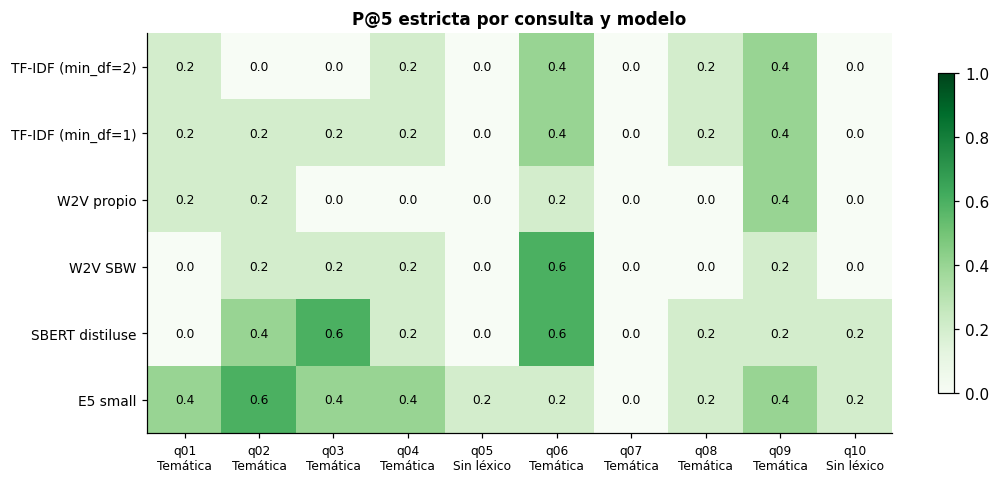

In [64]:
detalle = RES.pivot(index="id", columns="modelo", values="P@5")[list(BUSCADORES)]
detalle.insert(0, "azar", pd.Series({q["id"]: len(q["rel"]) / N for q in CONSULTAS}).reindex(detalle.index))
etiquetas_tipo = {"tematica": "Temática", "sin_solapamiento_lexico": "Sin léxico"}
detalle.insert(0, "tipo", pd.Series({q["id"]: etiquetas_tipo.get(q["tipo"], q["tipo"]) for q in CONSULTAS}).reindex(detalle.index))
print("P@5 estricta por consulta (* = sin señal: sin resultados o ranking empatado):")
marcas = RES.pivot(index="id", columns="modelo", values="sin_señal")[list(BUSCADORES)]
display(detalle.round(2).astype(str).where(~marcas.reindex(columns=detalle.columns, fill_value=False),
                                           detalle.round(2).astype(str) + "*"))

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(detalle[list(BUSCADORES)].to_numpy(dtype=float).T, cmap="Greens", vmin=0, vmax=1, aspect="auto")
consultas_por_id = {q["id"]: q for q in CONSULTAS}
ax.set_xticks(range(len(detalle)), [f"{i}\n{etiquetas_tipo.get(consultas_por_id[i]['tipo'], consultas_por_id[i]['tipo'])}" for i in detalle.index], fontsize=8)
ax.set_yticks(range(len(BUSCADORES)), list(BUSCADORES), fontsize=9)
for (r, c), v in np.ndenumerate(detalle[list(BUSCADORES)].to_numpy(dtype=float).T):
    ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("P@5 estricta por consulta y modelo"); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

E5 obtiene el mayor P@5 medio de este bloque, con 0,30. Conservar los términos que aparecen una sola vez mejora TF-IDF de 0,14 a 0,18.

También vemos una dificultad compartida: la consulta q07 queda sin aciertos en el top 5 de todos los modelos. El promedio no nos muestra ese fallo si no miramos la tabla por consulta.

### 9.2. Comparar modelo por modelo

Un promedio puede ocultar que un modelo acierta en unas consultas y falla en otras. Por eso comparamos las diferencias consulta por consulta y repetimos el muestreo con bootstrap, es decir, volvemos a tomar consultas del mismo conjunto con reemplazo.

Como solo tenemos diez, usamos esta comparación para entender lo que pasó acá, sin dar por hecho que pasará lo mismo en cualquier búsqueda.

Diferencia de P@5 contra TF-IDF (min_df=2) (por consulta: gana / empata / pierde):


,diferencia media,IC 95% inf,IC 95% sup,gana,empata,pierde
modelo,,,,,,
TF-IDF (min_df=1),0.04,0.00,0.10,2,8,0
W2V propio,-0.04,-0.12,0.04,1,6,3
W2V SBW,-0.00,-0.10,0.10,3,4,3
SBERT distiluse,0.10,-0.04,0.26,4,4,2
E5 small,0.16,0.02,0.30,6,3,1


Diferencia de P@5 contra TF-IDF (min_df=1) (por consulta: gana / empata / pierde):


,diferencia media,IC 95% inf,IC 95% sup,gana,empata,pierde
modelo,,,,,,
TF-IDF (min_df=2),-0.04,-0.10,0.00,0,8,2
W2V propio,-0.08,-0.14,-0.02,0,6,4
W2V SBW,-0.04,-0.12,0.04,1,6,3
SBERT distiluse,0.06,-0.04,0.18,4,4,2
E5 small,0.12,0.02,0.22,6,3,1


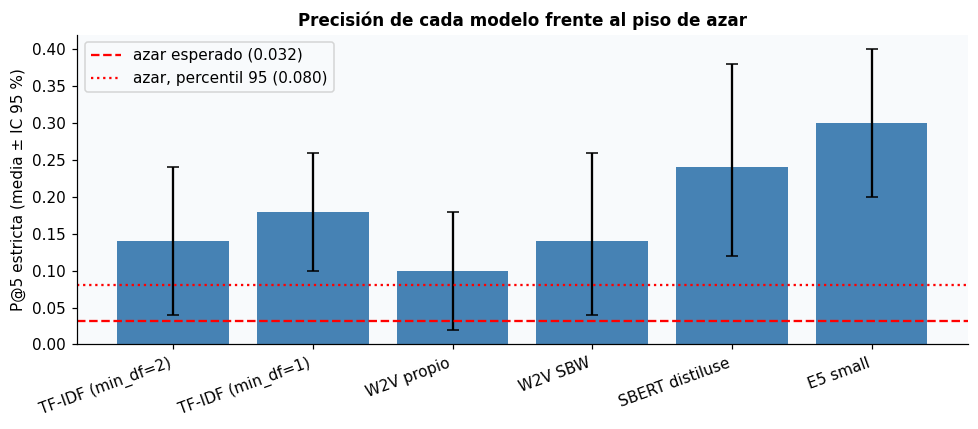

In [65]:
def comparar_con(base, metrica="P@5", rep=10_000):
    b = RES[RES.modelo == base].set_index("id")[metrica]
    filas = []
    for nombre in BUSCADORES:
        if nombre == base:
            continue
        d = (RES[RES.modelo == nombre].set_index("id")[metrica] - b).loc[b.index].to_numpy()
        boot = rng.choice(d, (rep, len(d)), replace=True).mean(axis=1)
        filas.append({"modelo": nombre, "diferencia media": d.mean(),
                      "IC 95% inf": np.percentile(boot, 2.5), "IC 95% sup": np.percentile(boot, 97.5),
                      "gana": int((d > 0).sum()), "empata": int((d == 0).sum()), "pierde": int((d < 0).sum())})
    return pd.DataFrame(filas).set_index("modelo")

for base in [n for n in BUSCADORES if n.startswith("TF-IDF")]:
    print(f"Diferencia de P@5 contra {base} (por consulta: gana / empata / pierde):")
    display(comparar_con(base).round(3))

medias = RES.groupby("modelo", sort=False)["P@5"].mean()
err = np.array([[medias[m] - np.percentile(rng.choice(RES[RES.modelo == m]["P@5"], (5000, len(CONSULTAS))).mean(1), 2.5),
                 np.percentile(rng.choice(RES[RES.modelo == m]["P@5"], (5000, len(CONSULTAS))).mean(1), 97.5) - medias[m]]
                for m in medias.index]).T
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(medias)), medias.values, yerr=err, capsize=4, color="steelblue")
ax.axhline(AZAR["P@5"][0], color="red", linestyle="--", label=f"azar esperado ({AZAR['P@5'][0]:.3f})")
ax.axhline(AZAR["P@5"][1], color="red", linestyle=":", label=f"azar, percentil 95 ({AZAR['P@5'][1]:.3f})")
ax.set_xticks(range(len(medias)), medias.index, rotation=20, ha="right")
ax.set_ylabel("P@5 estricta (media ± IC 95 %)"); ax.set_title("Precisión de cada modelo frente al piso de azar")
ax.legend(); plt.tight_layout(); plt.show()

### 9.3. Revisar libros sin marcar

También aparecen libros que todavía no tienen una marca en `queries.json`. Los exportamos para poder leerlos y decidir si cumplen el criterio de la consulta; luego podemos agregarlos como `agregados_pool`.

Mientras no los revisemos, no los contamos como relevantes en la métrica estricta. Al final del bloque abrimos una consulta que salió mal para ver dónde quedaron los libros que esperábamos encontrar.

In [66]:
pool = []
for q in CONSULTAS:
    vistos = {}
    for nombre in BUSCADORES:
        for i in RANKINGS[(nombre, q["id"])][0][:5]:
            if i not in q["rel"] | q["dud"] | q["pool"]:
                vistos.setdefault(i, []).append(nombre)
    for i, modelos in vistos.items():
        pool.append({"id": q["id"], "consulta": q["consulta"], "titulo": df.loc[i, "titulo"],
                     "url_libro": df.loc[i, "url_libro"], "traído por": len(modelos)})
POOL = pd.DataFrame(pool, columns=["id", "consulta", "titulo", "url_libro", "traído por"]).sort_values(["id", "traído por"], ascending=[True, False])
POOL.drop(columns="traído por").to_csv(CARPETA + "pool_sin_juzgar.csv", index=False)   # sin nombres de modelo: juicio a ciegas
print(f"{len(POOL)} pares (consulta, libro) sin juzgar → pool_sin_juzgar.csv")
display(POOL.groupby("id").size().rename("libros sin juzgar").to_frame().T)

119 pares (consulta, libro) sin juzgar → pool_sin_juzgar.csv


id,q01,q02,q03,q04,q05,q06,q07,q08,q09,q10
libros sin juzgar,11,9,8,12,18,10,15,16,14,6


In [67]:
def diagnosticar(qid, modelo, k=5):
    q = next(c for c in CONSULTAS if c["id"] == qid)
    idx, sims = BUSCADORES[modelo](q["consulta"], N)
    pos = {i: p for p, i in enumerate(idx, 1)}
    print(f"[{qid}] «{q['consulta']}» — {modelo}\nCriterio: {q['criterio']}\n")
    print("Top", k, ":")
    for p, (i, s) in enumerate(zip(idx[:k], sims[:k]), 1):
        marca = "✔ relevante" if i in q["rel"] else ("? dudoso" if i in q["dud"] else "")
        print(f"  {p}. ({s:.3f}) {df.loc[i, 'titulo'][:55]:<55} {marca}")
    print("\n¿Dónde quedaron los relevantes?")
    for i in sorted(q["rel"], key=lambda i: pos.get(i, float("inf"))):
        if i in pos:
            print(f"  puesto {pos[i]:>3} de {N}: {df.loc[i, 'titulo']}")
        else:
            print(f"  no recuperado: {df.loc[i, 'titulo']}")

# Ejemplo: la peor consulta del mejor modelo (cambiar por la que quieran analizar)
mejor = medias.drop([m for m in medias.index if m.startswith("TF-IDF")], errors="ignore").idxmax()
peor_q = RES[RES.modelo == mejor].sort_values(["P@5", "rango_1er_rel"], ascending=[True, False]).iloc[0]["id"]
diagnosticar(peor_q, mejor)

[q07] «primer encuentro y comunicación con una inteligencia alienígena» — E5 small
Criterio: El centro del relato es el contacto con una inteligencia no humana: descubrirla, intentar entenderla o comunicarse con ella (no una guerra de invasión).

Top 5 :
  1. (0.849) Una mirada a Alice B. Sheldon                           ? dudoso
  2. (0.845) El gran espectáculo                                     ? dudoso
  3. (0.836) La utopía de Turing                                     
  4. (0.834) Un puente sobre el tiempo                               
  5. (0.832) Una memoria llamada Imperio                             

¿Dónde quedaron los relevantes?
  puesto  14 de 200: La voz del espacio
  puesto  21 de 200: Intermnemosis
  puesto  51 de 200: El problema de los Tres Cuerpos (Edición ilustrada)
  puesto  62 de 200: ¡Vaya planeta!
  puesto 141 de 200: Ruido fractal


En q07, E5 deja el primer libro relevante en el puesto 14. Los puntajes de los primeros resultados son altos, pero ninguno está marcado como relevante y dos son dudosos.

Así vemos que una similitud alta no alcanza para saber si un libro cumple el criterio de la búsqueda. Por otra parte, nos quedan 116 pares consulta–libro sin juzgar para revisar.

<a id="hibrida"></a>
## 10. Combinar búsquedas

Hasta acá probamos buscar por palabras y por significado por separado. Ahora juntamos la búsqueda semántica de E5 con la búsqueda por palabras de PostgreSQL, llamada **FTS** (*full-text search*).

Para combinar sus resultados usamos **RRF**: cada libro recibe puntos según el puesto que ocupa en cada lista. Así no necesitamos comparar directamente los puntajes de dos buscadores que usan escalas distintas.

### 10.1. Preparar la búsqueda por palabras

Preparamos la búsqueda por palabras usando las mismas sinopsis que para los embeddings. PostgreSQL las convierte en `tsvector` con reglas de español: quita palabras vacías y reduce algunas variantes a una forma común.

Miramos un ejemplo para ver cómo queda el texto y comparamos pedir todas las palabras de una consulta con pedir cualquiera de ellas.

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from psycopg import sql

conn.execute("ALTER TABLE books ADD COLUMN IF NOT EXISTS tsv tsvector;")
with conn.transaction():
    conn.cursor().executemany(
        "UPDATE books SET tsv = to_tsvector('spanish', %s) WHERE url_libro = %s;",
        list(zip(df["texto_crudo"], df["url_libro"])))
conn.execute("CREATE INDEX IF NOT EXISTS books_tsv_idx ON books USING gin (tsv);")

ejemplo = conn.execute("SELECT titulo, left(tsv::text, 160) FROM books WHERE titulo = 'Patrulla galactica';").fetchone()
print(f"tsvector de «{ejemplo[0]}» (comienzo):\n  {ejemplo[1]}…")
y, o = conn.execute("""SELECT plainto_tsquery('spanish', %(texto)s),
                              replace(plainto_tsquery('spanish', %(texto)s)::text, ' & ', ' | ')::tsquery""",
                    {"texto": "una novela sobre piratas espaciales"}).fetchone()
print(f"Consulta «una novela sobre piratas espaciales»\n  con Y (todas las palabras): {y}\n  con O (alguna palabra):     {o}")

tsvector de «Patrulla galactica» (comienzo):
  'amenaz':10 'asalt':8 'aun':25 'bas':43 'boskon':7 'boskonian':45 'civiliz':16,73 'crucer':29 'defens':54 'derrot':24 'des':56 'descubr':41 'dirig':18 'espaci':…
Consulta «una novela sobre piratas espaciales»
  con Y (todas las palabras): 'novel' & 'pirat' & 'espacial'
  con O (alguna palabra):     'novel' | 'pirat' | 'espacial'


Elegimos buscar coincidencias con cualquiera de las palabras. Si exigiéramos todas, una sinopsis podría quedar fuera por no usar exactamente la misma forma de expresar el tema.

Ordenamos con `ts_rank` y normalizamos por longitud para reducir la ventaja de las sinopsis que simplemente tienen más texto.

In [69]:
TSQUERY_O = "replace(plainto_tsquery('spanish', %(texto)s)::text, ' & ', ' | ')::tsquery"

def buscar_fts(consulta, k):
    filas = conn.execute(f"""
        SELECT id, ts_rank(tsv, q, 1) AS puntaje
        FROM books, (SELECT {TSQUERY_O} AS q) c
        WHERE tsv @@ q AND id = ANY(%(ids_actuales)s)
        ORDER BY puntaje DESC, id
        LIMIT %(k)s;""", {"texto": consulta, "k": k, "ids_actuales": list(fila_de_book_id)}).fetchall()
    return [fila_de_book_id[i] for i, _ in filas], [p for _, p in filas]

idx, pts = buscar_fts("una novela sobre piratas", 5)
print("FTS — «una novela sobre piratas»:", [df.loc[i, "titulo"] for i in idx])

FTS — «una novela sobre piratas»: ['El Planeta prodigioso', 'La guerra de los mundos (Ilustrado por Alvim Corrêa)', 'Somnium', 'El mundo perdido (trad. Amando Lázaro Ros)', 'El talón de hierro (ed. Jesús Isaías Gómez)']


### 10.2. Combinar las listas con RRF

Una vez que tenemos las dos listas, las combinamos. Cada libro suma `1 / (60 + posición)` por cada lista en la que aparece; cuanto más arriba esté, más puntos recibe.

Traemos hasta 50 candidatos por buscador y empezamos dándoles el mismo peso. Miramos los puestos de origen para entender por qué un libro sube en el resultado combinado.

In [70]:
K_RRF = 60
PROFUNDIDAD = 50          # cuántos candidatos aporta cada método a la fusión
MODELO_HIBRIDO = "emb_e5" if "emb_e5" in CODIFICADORES else MODELO_POR_DEFECTO

def buscar_hibrida(consulta, k=5, modelo=None, peso_sem=1.0, peso_lex=1.0, detalle=False):
    modelo = modelo or MODELO_HIBRIDO
    if peso_sem < 0 or peso_lex < 0 or peso_sem + peso_lex <= 0:
        raise ValueError("Los pesos deben ser no negativos y al menos uno positivo")
    q = np.asarray(CODIFICADORES[modelo](consulta), dtype=np.float32)
    hay_vector = bool(np.isfinite(q).all() and np.linalg.norm(q) > 0)
    semantica = (sql.SQL("""
        SELECT book_id, row_number() OVER (ORDER BY embedding <=> %(q)s, book_id) AS rango
        FROM {t} ORDER BY embedding <=> %(q)s, book_id LIMIT %(n)s""").format(t=sql.Identifier(modelo))
        if hay_vector and peso_sem > 0 else sql.SQL("SELECT NULL::int AS book_id, NULL::bigint AS rango WHERE false"))
    consulta_sql = sql.SQL("""
        WITH semantica AS ({semantica}),
        lexica AS (
            SELECT id AS book_id,
                   row_number() OVER (ORDER BY ts_rank(tsv, c.q, 1) DESC, id) AS rango
            FROM books, (SELECT {tsq} AS q) c
            WHERE tsv @@ c.q AND id = ANY(%(ids_actuales)s) AND %(pl)s > 0
            ORDER BY ts_rank(tsv, c.q, 1) DESC, id
            LIMIT %(n)s)
        SELECT COALESCE(s.book_id, l.book_id) AS book_id,
               COALESCE(%(ps)s::float8 / (%(krrf)s::float8 + s.rango), 0)
             + COALESCE(%(pl)s::float8 / (%(krrf)s::float8 + l.rango), 0) AS puntaje,
               s.rango AS rango_semantico, l.rango AS rango_lexico
        FROM semantica s FULL OUTER JOIN lexica l ON s.book_id = l.book_id
        ORDER BY puntaje DESC, book_id
        LIMIT %(k)s;""").format(semantica=semantica, tsq=sql.SQL(TSQUERY_O))
    # float8: con enteros, Postgres haría división entera y 1 / 61 daría 0
    params = {"texto": consulta, "n": PROFUNDIDAD, "k": k, "krrf": float(K_RRF),
              "ps": float(peso_sem), "pl": float(peso_lex), "ids_actuales": list(fila_de_book_id)}
    if hay_vector:
        params["q"] = q
    filas = conn.execute(consulta_sql, params).fetchall()
    if detalle:
        return pd.DataFrame([(df.loc[fila_de_book_id[b], "titulo"], p, rs, rl) for b, p, rs, rl in filas],
                            columns=["titulo", "puntaje RRF", "puesto semántico", "puesto léxico"])
    return [fila_de_book_id[b] for b, *_ in filas], [p for _, p, *_ in filas]

print(f"Híbrida = {MODELO_HIBRIDO} + full-text, K_RRF = {K_RRF}, profundidad = {PROFUNDIDAD}")
display(buscar_hibrida("una novela sobre piratas", 5, detalle=True))
display(buscar_hibrida("autómatas con voluntad e identidad", 5, detalle=True))

Híbrida = emb_e5 + full-text, K_RRF = 60, profundidad = 50


,titulo,puntaje RRF,puesto semántico,puesto léxico
0,EI huracán cósmico,0.027206,20,8
1,Un puente sobre el tiempo,0.027052,8,21
2,Regreso a las estrellas,0.026430,21,11
3,Herederos del recuerdo,0.026333,2,38
4,Yo viví en el año 3000,0.026102,1,43


,titulo,puntaje RRF,puesto semántico,puesto léxico
0,Missitalia,0.026023,34.0,5.0
1,La chica del átomo de oro,0.025152,40.0,6.0
2,Protocolo rebelde,0.016393,1.0,NaN
3,Los seis dedos del tiempo,0.016393,NaN,1.0
4,La guerra solar,0.016129,NaN,2.0


In [71]:
nombre_sem = {"emb_e5": "E5 small", "emb_sbert": "SBERT distiluse", "emb_w2v_sbw": "W2V SBW",
              "emb_w2v_propio": "W2V propio"}[MODELO_HIBRIDO]
COMPARADOS = {
    "TF-IDF (min_df=1)": globals().get("buscar_tfidf_min1"),
    "Full-text Postgres": buscar_fts,
    nombre_sem: BUSCADORES.get(nombre_sem) if "BUSCADORES" in globals() else None,
    "Híbrida RRF": lambda c, k: buscar_hibrida(c, k),
}
COMPARADOS = {n: f for n, f in COMPARADOS.items() if f is not None}

filas = []
for nombre, f in COMPARADOS.items():
    for q in CONSULTAS:
        idx, _ = f(q["consulta"], 10)
        filas.append({"modelo": nombre, "id": q["id"], "tipo": q["tipo"],
                      "P@5": p_at_k(idx, q["rel"], 5), "P@5_laxa": p_at_k(idx, q["rel"] | q["dud"], 5),
                      "P@10": p_at_k(idx, q["rel"], 10), "top5": idx[:5]})
RES_H = pd.DataFrame(filas)

tabla = RES_H.groupby("modelo", sort=False)[["P@5", "P@5_laxa", "P@10"]].mean()
tabla.loc["Azar (esperado)"] = [AZAR["P@5"][0], AZAR["P@5_laxa"][0], AZAR["P@10"][0]]
display(tabla.round(3))
display(RES_H.pivot_table(index="modelo", columns="tipo", values="P@5", aggfunc="mean", sort=False).round(3))
display(RES_H.pivot(index="id", columns="modelo", values="P@5")[list(COMPARADOS)].round(1))

# Comparación pareada de la híbrida contra cada componente (bootstrap sobre consultas)
rng_h = np.random.default_rng(7)
base_h = RES_H[RES_H.modelo == "Híbrida RRF"].set_index("id")["P@5"]
filas = []
for nombre in COMPARADOS:
    if nombre == "Híbrida RRF":
        continue
    d = (base_h - RES_H[RES_H.modelo == nombre].set_index("id")["P@5"]).loc[base_h.index].to_numpy()
    boot = rng_h.choice(d, (10_000, len(d))).mean(axis=1)
    filas.append({"híbrida contra": nombre, "diferencia media": d.mean(),
                  "IC 95% inf": np.percentile(boot, 2.5), "IC 95% sup": np.percentile(boot, 97.5),
                  "gana": int((d > 0).sum()), "empata": int((d == 0).sum()), "pierde": int((d < 0).sum())})
print("Diferencia de P@5 (híbrida − otro método):")
display(pd.DataFrame(filas).set_index("híbrida contra").round(3))

,P@5,P@5_laxa,P@10
modelo,,,
TF-IDF (min_df=1),0.180,0.240,0.120
Full-text Postgres,0.300,0.380,0.200
E5 small,0.300,0.440,0.210
Híbrida RRF,0.340,0.500,0.260
Azar (esperado),0.032,0.058,0.032


tipo,tematica,sin_solapamiento_lexico
modelo,,
TF-IDF (min_df=1),0.225,0.0
Full-text Postgres,0.375,0.0
E5 small,0.325,0.2
Híbrida RRF,0.400,0.1


modelo,TF-IDF (min_df=1),Full-text Postgres,E5 small,Híbrida RRF
id,,,,
q01,0.2,0.6,0.4,0.6
q02,0.2,0.6,0.6,0.6
q03,0.2,0.4,0.4,0.4
q04,0.2,0.0,0.4,0.4
q05,0.0,0.0,0.2,0.2
q06,0.4,0.6,0.2,0.6
q07,0.0,0.0,0.0,0.0
q08,0.2,0.4,0.2,0.2
q09,0.4,0.4,0.4,0.4


Diferencia de P@5 (híbrida − otro método):


,diferencia media,IC 95% inf,IC 95% sup,gana,empata,pierde
híbrida contra,,,,,,
TF-IDF (min_df=1),0.16,0.06,0.26,6,4,0
Full-text Postgres,0.04,-0.04,0.14,2,7,1
E5 small,0.04,-0.04,0.14,2,7,1


In [72]:
tabla_resultados(tabla, "Búsqueda híbrida y sus componentes")

,P@5,P@5_laxa,P@10
modelo,,,
TF-IDF (min_df=1),0.180,0.240,0.120
Full-text Postgres,0.300,0.380,0.200
E5 small,0.300,0.440,0.210
Híbrida RRF,0.340,0.500,0.260
Azar (esperado),0.032,0.058,0.032


### 10.3. Ver qué aporta cada buscador

Para entender qué aporta la combinación, contamos los relevantes que encuentra solo la búsqueda semántica, solo la búsqueda por palabras y ambas.

Miramos sus top 5, pero recordamos que RRF recibe hasta 50 candidatos de cada buscador: también puede hacer subir un libro que estaba más abajo.

In [73]:
top = RES_H.set_index(["modelo", "id"])["top5"]
filas = []
for q in CONSULTAS:
    a_sem = set(top[(nombre_sem, q["id"])]) & q["rel"] if nombre_sem in COMPARADOS else set()
    a_lex = set(top[("Full-text Postgres", q["id"])]) & q["rel"]
    a_hib = set(top[("Híbrida RRF", q["id"])]) & q["rel"]
    filas.append({"id": q["id"], "solo semántica": len(a_sem - a_lex), "ambas": len(a_sem & a_lex),
                  "solo léxica": len(a_lex - a_sem), "unión": len(a_sem | a_lex), "híbrida": len(a_hib)})
comp = pd.DataFrame(filas).set_index("id")
comp.loc["TOTAL"] = comp.sum()
print("Relevantes en los top-5: solapamiento observado; la fusión usa profundidad 50 por componente:")
display(comp)

Relevantes en los top-5: solapamiento observado; la fusión usa profundidad 50 por componente:


,solo semántica,ambas,solo léxica,unión,híbrida
id,,,,,
q01,1,1,2,4,3
q02,1,2,1,4,3
q03,0,2,0,2,2
q04,2,0,0,2,2
q05,1,0,0,1,1
q06,0,1,2,3,3
q07,0,0,0,0,0
q08,0,1,1,2,1
q09,1,1,1,3,2


Cada componente encuentra siete relevantes que el otro no tiene en su top 5, y comparten ocho. Hay resultados que se complementan, pero la combinación no reúne automáticamente todos esos aciertos: su top 5 suma 17, frente a los 22 de la unión.

### 10.4. Probar distintos pesos

Probamos darle más peso a un buscador o al otro y vemos cómo cambia P@5. Los extremos `1:0` y `0:1` nos sirven para recuperar cada búsqueda por separado.

Si un peso mejora acá, todavía tendríamos que probarlo con otras consultas antes de quedarnos con él.

In [74]:
pesos = [(1, 0), (2, 1), (1, 1), (1, 2), (0, 1)]
sens = []
for ps, pl in pesos:
    p5 = np.mean([p_at_k(buscar_hibrida(q["consulta"], 5, peso_sem=ps, peso_lex=pl)[0], q["rel"], 5)
                  for q in CONSULTAS])
    sens.append({"peso semántico : léxico": f"{ps}:{pl}", "P@5": p5})
display(pd.DataFrame(sens).set_index("peso semántico : léxico").round(3))
print("1:0 equivale a la búsqueda semántica sola (salvo consultas sin vector, en W2V) y 0:1 al full-text solo.")

,P@5
peso semántico : léxico,
1:0,0.30
2:1,0.38
1:1,0.34
1:2,0.30
0:1,0.30


1:0 equivale a la búsqueda semántica sola (salvo consultas sin vector, en W2V) y 0:1 al full-text solo.


In [75]:
for q_control in ["una novela sobre piratas", "zzzxqvpalabrainexistente"]:
    assert buscar_hibrida(q_control, 5, peso_sem=0, peso_lex=1)[0] == buscar_fts(q_control, 5)[0]
print("Control de fusión: peso 0:1 coincide con full-text, incluida una consulta sin coincidencias.")

Control de fusión: peso 0:1 coincide con full-text, incluida una consulta sin coincidencias.


En estas consultas, darle el doble de peso a la parte semántica (`2:1`) sube P@5 a 0,38. Lo tomamos como una prueba útil para entender los pesos; para elegirlos definitivamente nos harían falta otras consultas.

El control con `0:1` también pasa: obtenemos los mismos resultados que con FTS solo, incluso cuando no hay coincidencias.

### Resultados de las búsquedas

Reunimos los resultados para cerrar los ejercicios de búsqueda. En estas consultas, RRF llega a un P@5 de 0,34, frente a 0,30 de E5 y de FTS por separado.

La mejora es pequeña y no aparece en todas las consultas. Nos quedamos también con los casos que fallaron: nos ayudan a ver qué libros convendría revisar y dónde la combinación no resolvió el problema.

In [76]:
mejor_recuperacion = RES.groupby("modelo")["P@5"].mean().sort_values(ascending=False)

display(Markdown(f"En estas consultas, el mayor **P@5** es **{mejor_recuperacion.iloc[0]:.3f}**, de **{mejor_recuperacion.index[0]}**. Consultas: **{len(CONSULTAS)}**; pares consulta–libro por revisar: **{len(POOL)}**."))

display(Markdown(f"**Libros:** {len(df)}; **sinopsis únicas:** {grupos_sinopsis.nunique()}."))

display(Markdown(f"**Sinopsis truncadas:** Distiluse **{trunc.truncado.mean():.1%}**; E5 **{trunc_e5.truncado.mean():.1%}**."))

En estas consultas, el mayor **P@5** es **0.300**, de **E5 small**. Consultas: **10**; pares consulta–libro por revisar: **119**.

**Libros:** 200; **sinopsis únicas:** 199.

**Sinopsis truncadas:** Distiluse **84.0%**; E5 **2.0%**.

In [77]:
promedios_h = RES_H.groupby("modelo")["P@5"].mean()
display(Markdown(f"**P@5** — RRF: **{promedios_h['Híbrida RRF']:.3f}**; búsqueda semántica: **{promedios_h[nombre_sem]:.3f}**; FTS: **{promedios_h['Full-text Postgres']:.3f}**."))

**P@5** — RRF: **0.340**; búsqueda semántica: **0.300**; FTS: **0.300**.

<a id="archivos"></a>
## 11. Guardar archivos

Para terminar, guardamos las matrices de embeddings, el modelo propio y las tablas que fuimos generando. Así podemos volver a usar los vectores y revisar los libros pendientes sin repetir todo el trabajo.

Armamos **`TP2_artifacts.zip`** y lo descargamos desde Colab. Incluimos también los dos archivos de entrada para tener todo junto; el archivo grande de SBW queda fuera del ZIP. Los resultados se mantienen en este notebook, junto al código que los produjo.

In [78]:
import shutil
from zipfile import ZipFile, ZIP_DEFLATED

EXPORT_DIR = ARTIFACT_DIR
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
archivos = ["libros.csv", "queries.json", "pool_sin_juzgar.csv",
            "emb_w2v_propio.npy", "emb_w2v_sbw.npy", "emb_sbert_distiluse.npy", "emb_e5_small.npy",
            "cobertura_w2v.csv", "truncado_distiluse.csv"]
exportados = []
for nombre in archivos:
    origen = DATA_DIR / nombre
    if origen.is_file():
        destino = EXPORT_DIR / nombre
        shutil.copy2(origen, destino)
        exportados.append(destino)
        print(f"Guardado: {nombre}")
ruta_modelo = EXPORT_DIR / "w2v_propio.model"
w2v.save(str(ruta_modelo))
exportados.extend(sorted(EXPORT_DIR.glob("w2v_propio.model*")))
print("Guardado: w2v_propio.model")

ZIP_PATH = DATA_DIR / "TP2_artifacts.zip"
with ZipFile(ZIP_PATH, "w", compression=ZIP_DEFLATED) as archivo_zip:
    for ruta in exportados:
        archivo_zip.write(ruta, arcname=ruta.name)
print(f"ZIP listo: {ZIP_PATH.name} ({ZIP_PATH.stat().st_size / 1e6:.1f} MB)")

Guardado: libros.csv
Guardado: queries.json
Guardado: pool_sin_juzgar.csv
Guardado: emb_w2v_propio.npy
Guardado: emb_w2v_sbw.npy
Guardado: emb_sbert_distiluse.npy
Guardado: emb_e5_small.npy
Guardado: cobertura_w2v.csv
Guardado: truncado_distiluse.csv
Guardado: w2v_propio.model
ZIP listo: TP2_artifacts.zip (2.8 MB)


In [79]:
tabla_resultados(pd.DataFrame([
    {"Archivo": ruta.name, "Tamaño (KiB)": ruta.stat().st_size / 1024}
    for ruta in exportados
]).set_index("Archivo"), "Archivos para conservar", precision=1)

# Si el navegador bloquea la descarga, también encontramos el ZIP en el panel de archivos.
try:
    files.download(str(ZIP_PATH))
except Exception:
    print("Descargá TP2_artifacts.zip desde el panel de archivos de Colab.")

,Tamaño (KiB)
Archivo,
libros.csv,229.4
queries.json,21.7
pool_sin_juzgar.csv,17.3
emb_w2v_propio.npy,78.2
emb_w2v_sbw.npy,234.5
emb_sbert_distiluse.npy,400.1
emb_e5_small.npy,300.1
cobertura_w2v.csv,16.8
truncado_distiluse.csv,16.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>